Notebook for checking activations of finded expert's clusters. How they are similar of distinct?

In [1]:
import matplotlib.pyplot as plt
import numpy as np 
import os 
from pathlib import Path 
import torch 
from typing import *
import seaborn as sns
from sklearn.metrics import pairwise_distances
import ast
import pandas as pd
from sklearn.decomposition import PCA 
from sklearn.manifold import TSNE, Isomap, MDS

In [2]:
class ActivationParser:
    def __init__(self, root: Path, layer_prefix: str, task_mapping: dict = None):
        self.root = root if isinstance(root, Path) else Path(root)
        self.layer_prefix = layer_prefix
        self.task_mapping = task_mapping or {}
        self.task_to_idx = {v: k for k, v in self.task_mapping.items()}
        self.expert_infix = 'mlp.experts'
        self.gate_infix = 'mlp.gate'
        self.expert_to_idx_num = {task: {} for task in self.task_mapping}
      
    def parse_experts(self, layer: int, task='', as_gen=False):
        gen = self._parse_kind(layer, task)
        if as_gen:
            return gen 
        return dict(gen)
    
    def parse_gate(self, layer: int, task=''):
        # return next(iter(self._parse_kind(layer, task, self.gate_infix)))[1]
        path: Path = f'{self.root}/{self.layer_prefix}.{layer}.{self.gate_infix}'
        task = self.task_to_idx.get(task, 0) #TODO NOTE была ошибка с task_mapping вместо task_to_idx
        # print("TASK in parse gate!", task)
        # for expert in self.root.iterdir():
        #     if not expert.name.endswith(self.gate_infix):
        #         continue
        file = path + "/" + f'{task}.pth'
        t = torch.load(file, map_location='cuda:0').cpu()
        return t
        raise Exception('no gate found')

    def _parse_kind(self, layer, task):
        path: Path = f'{self.layer_prefix}.{layer}.{self.expert_infix}'
        task = self.task_to_idx[task]
        for expert in self.root.iterdir():
            if not str(path) in expert.name:
                continue
            n = int(expert.name.split('.')[-1])
            file = expert /  f'{task}.pth'
            if file.exists():
                t = torch.load(file, map_location='cuda:0').cpu()
                self.expert_to_idx_num[task][n] = t.size(0)
                yield n, t

    def get_experts_per_token(self, gate_output, k=4):
        return torch.topk(gate_output, k, dim=-1).indices
    
    def count_expert_calls(self, experts: Dict[int, torch.Tensor]):
        return {expert: value.size(0) for expert, value in experts.items()}
  
    def get_token_routing_map(self, layer: int, task: str = '', k: int = 4):
        """
        Returns a list of length = num_tokens.
        For each token i:
            token_routing[i] = list of tuples: (expert_id, row_idx_in_expert_tensor, gate_weight)
        
        gate_weight = softmax of the top-k logits for that token-expert pair
        (standard Mixtral / DeepSeek / most modern MoE routing)
        """
        gate_output = self.parse_gate(layer, task)          # (num_tokens, num_experts)
        n_tokens = gate_output.shape[0]
        num_experts = gate_output.shape[1]

        # 1. Get top-k experts + raw scores
        topk_values, topk_indices = torch.topk(gate_output, k, dim=-1)   # both (n_tokens, k)

        # 2. Convert raw top-k scores → actual routing weights (softmax per token)
        routing_weights = torch.softmax(topk_values, dim=-1)             # (n_tokens, k)

        # 3. Build per-expert list of tokens that were routed to it
        expert_to_tokens = [[] for _ in range(num_experts)]
        for t in range(n_tokens):
            for i in range(k):
                e = topk_indices[t, i].item()
                expert_to_tokens[e].append(t)

        # 4. For each expert, sort tokens by original index (this matches how activations are saved)
        expert_to_sorted_tokens = [sorted(tok_list) for tok_list in expert_to_tokens]

        # 5. Fast lookup: token → row index inside that expert's tensor
        expert_to_token2row = []
        for e in range(num_experts):
            token2row = {token: row_idx for row_idx, token in enumerate(expert_to_sorted_tokens[e])}
            expert_to_token2row.append(token2row)

        # 6. Build final map
        token_routing = []
        for t in range(n_tokens):
            token_list = []
            for i in range(k):
                e = topk_indices[t, i].item()
                weight = routing_weights[t, i].item()
                row_idx = expert_to_token2row[e][t]
                token_list.append((e, row_idx, weight))
            token_routing.append(token_list)

        return token_routing
           
    def get_experts_coactivation(self, layer, topk=2, verbose=False):
        '''For each task/topic returns list of topk experts selected for each token.'''
        experts_coactivation = []
        for task_name in self.task_to_idx.keys():
            for expert_tuple in self.get_token_routing_map(layer, task_name, topk):
                experts_coactivation.append([expert_tuple[i][0] for i in range(topk)])
            if (verbose):
                print(experts_coactivation.__len__())
        return experts_coactivation

    def get_all_expert_embeddings(self, tasks: List[str], layers=None):
        res = []
        layers = layers or [0]

        for task in tasks:
            print(task, '!!!')
            for layer in layers:
                experts = self.parse_experts(layer, task)
                #print("experts", experts)
                embeddings  = experts
                for expert, embeddings in embeddings.items():
                    for token_idx, token_emb in enumerate(embeddings):
                        res.append(
                            (task, layer, expert, *token_emb.cpu().numpy())
                        )
                #print("res", res)
        res = pd.DataFrame(res, columns=('task', 'layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 3)]))
        return res 
    
    def get_tasks_expert_embeddings(self, tasks: List[str], aggregation: Literal['mean', 'max'], layers=None):
        res = []
        layers = layers or [0]

        for task in tasks:
            print(task, '!!!')
            for layer in layers:
                experts = self.parse_experts(layer, task)

                if aggregation == 'max':
                    embeddings = {e: activations[torch.argmax(torch.linalg.norm(activations, dim=-1))] for e, activations in experts.items()}
                elif aggregation == 'mean':
                    embeddings = {e: torch.mean(e_vals, dim=0) for e, e_vals in experts.items()}
                else:
                    raise ValueError(f'Unknown aggregation: {aggregation}. Supported max, mean')
                for expert, embedding in embeddings.items():
                    res.append(
                        (task, layer, expert, *embedding.cpu().numpy())
                    )
        res = pd.DataFrame(res, columns=('task', 'layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 3)]))
        return res 


In [3]:
file: Path = Path("../../activations_moe_60_experts/model.layers.0.mlp.experts.0/" + f'{0}.pth')
t = 0
if file.exists():
    t = torch.load(file, map_location='cuda:0').cpu()
t

tensor([[ 0.0598, -0.0755,  0.0207,  ..., -0.0018,  0.0476, -0.0067],
        [-0.0989, -0.0221,  0.0396,  ..., -0.0368,  0.0229, -0.0151],
        [ 0.0445, -0.0933,  0.0228,  ..., -0.0884,  0.0600, -0.0417],
        ...,
        [ 0.0199,  0.0418,  0.0085,  ..., -0.0164, -0.0197, -0.0293],
        [-0.0049, -0.0071, -0.0046,  ..., -0.0096,  0.0078, -0.0062],
        [-0.0044,  0.0012, -0.0043,  ..., -0.0005,  0.0052, -0.0062]],
       dtype=torch.float16)

In [4]:
mapping = dict(zip(range(10), [
           "anatomy", 
            "conceptual_physics",
            "human_sexuality",
            "machine_learning", 
            "management", 
            "marketing", 
            "nutrition",
             "philosophy",
            "us_foreign_policy",
              "world_religions"
]
))
parser = ActivationParser('../../activations_moe_60_experts', 'model.layers', mapping)

In [5]:
def get_indices_from_gate(gate: torch.Tensor, exp_to_k: dict, total_experts: int):
    exp_to_indices = {}
    exp_to_gate_values = {}
    for i in range(total_experts):
        k = exp_to_k.get(i, 0)
        topk = torch.topk(gate[:, i], k)
        exp_to_gate_values[i] = topk.values
        exp_to_indices[i] = topk.indices
    indices_in_batch = {}
    for exp, indices in exp_to_indices.items():
        indices_in_initial_order = torch.sort(indices, descending=False).values
        indices_in_batch[exp] = torch.argsort(gate[indices_in_initial_order, exp], descending=True)
    return exp_to_indices, exp_to_gate_values, indices_in_batch

In [6]:
#NOTE MEAN EMBEDDINGS!!! For every expert in every topic MEAN
all_topics = ["anatomy", 
            "conceptual_physics",
            "human_sexuality",
            "machine_learning", 
            "management", 
            "marketing", 
            "nutrition",
             "philosophy",
            "us_foreign_policy",
              "world_religions"]

embeddings = parser.get_tasks_expert_embeddings(all_topics, 'mean', range(60))

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!


KeyboardInterrupt: 

In [ ]:
embeddings.head()

/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,task,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,anatomy,0,58,-0.034698,0.008263,-0.008232,0.032959,-0.016968,0.003006,-0.007011,...,-0.007492,0.012611,-0.005661,-0.004398,0.003786,-0.015198,0.013184,-0.014343,-0.013016,-0.020798
1,anatomy,0,53,0.051239,0.006706,0.073608,0.017761,0.012924,-0.000837,0.043365,...,0.004765,-0.051483,0.008659,0.055756,0.007030,0.031433,0.017471,-0.006165,0.012619,0.040222
2,anatomy,0,41,-0.006878,-0.006554,-0.020432,0.016235,0.005146,0.002029,-0.003019,...,-0.034027,0.010666,-0.018814,0.006561,-0.000071,0.008087,0.012871,-0.003654,0.022095,0.023300
3,anatomy,0,12,0.008255,0.004719,-0.001733,-0.003513,0.013786,-0.002811,-0.014626,...,0.006149,-0.007347,0.004078,-0.000953,0.009178,0.002243,-0.002640,0.005081,-0.001487,0.013329
4,anatomy,0,18,-0.029877,-0.033630,-0.070007,0.002409,-0.012001,-0.019424,0.021011,...,-0.059326,-0.045837,-0.021744,-0.040405,-0.005573,0.009422,-0.073975,-0.054260,0.014290,0.021759


In [ ]:
embs_only = embeddings.drop(['task', 'layer', 'expert'], axis=1)
embs_only_full = pd.DataFrame(embs_only)
pca = PCA(64, random_state=1)
embs_only = pca.fit_transform(embs_only)

In [ ]:
experts_indices = parser.get_experts_coactivation(0, 4)


def get_experts_coactivation_dict(experts_indices):
    count_dict = {}
    for pair in experts_indices:
        if (pair[0] >= pair[1]):
            pair_index = (pair[0] * 10 + pair[1])
        else:
            pair_index = (pair[1] * 10 + pair[0])
        count_dict[pair_index] = count_dict.get(pair_index, 0) + 1

    return count_dict

count_dict = get_experts_coactivation_dict(experts_indices)

def get_experts_coactivation_dict_any_num_experts(experts_indices):
    '''Returns exact count of same coactivations expert order'''
    count_dict = {}
    for expert_tuple in experts_indices:
        tuple_ind = str(expert_tuple)
        count_dict[tuple_ind] = count_dict.get(tuple_ind, 0) + 1

    return count_dict

def get_experts_coactivation_dict_any_num_experts_without_order(experts_indices):
    '''Count the same tuples without order of experts inside that tuple'''
    count_dict = {}
    for expert_tuple in experts_indices:
        tuple_ind = str(sorted(expert_tuple))
        count_dict[tuple_ind] = count_dict.get(tuple_ind, 0) + 1

    return count_dict

def get_experts_most_pop(experts_indices):
    count_dict = {}
    for expert_tuple in experts_indices:
        for exp in expert_tuple:
            count_dict[exp] = count_dict.get(exp, 0) + 1

    return count_dict

count_dict_all = get_experts_coactivation_dict_any_num_experts(experts_indices)
print(count_dict_all)
# plt.figure(figsize=(20, 20))
# plt.title("Популярность четвёрок порядок учитывается")
# plt.xticks(rotation=90)
# plt.plot(sorted(count_dict_all, key=count_dict_all.get, reverse=True), list(sorted(count_dict_all.values(), reverse=True)))

# print(count_dict)
most_pop_exp = get_experts_most_pop(experts_indices)
print(most_pop_exp)
print(sorted(most_pop_exp, key=most_pop_exp.get, reverse=True))


{'[33, 4, 26, 14]': 30, '[4, 26, 20, 1]': 25, '[51, 37, 24, 0]': 24, '[46, 51, 8, 58]': 24, '[50, 29, 58, 49]': 3, '[36, 2, 49, 29]': 2, '[25, 41, 37, 56]': 1, '[8, 5, 44, 58]': 2, '[49, 48, 0, 14]': 1, '[38, 40, 11, 3]': 1, '[43, 2, 44, 20]': 1, '[34, 47, 10, 20]': 4, '[25, 58, 55, 17]': 1, '[58, 11, 40, 38]': 1, '[32, 58, 56, 57]': 1, '[5, 38, 26, 44]': 1, '[18, 38, 33, 44]': 25, '[18, 33, 38, 44]': 5, '[33, 35, 23, 13]': 20, '[33, 11, 35, 23]': 2, '[33, 23, 35, 11]': 2, '[33, 23, 35, 24]': 6, '[33, 35, 23, 11]': 1, '[33, 35, 44, 11]': 3, '[33, 35, 23, 44]': 36, '[33, 23, 35, 44]': 43, '[33, 23, 4, 35]': 8, '[4, 33, 23, 35]': 18, '[51, 33, 35, 13]': 4, '[50, 29, 49, 4]': 1, '[36, 2, 19, 29]': 1, '[23, 0, 2, 19]': 1, '[37, 28, 35, 44]': 1, '[8, 46, 58, 28]': 1, '[29, 43, 48, 20]': 1, '[51, 37, 22, 35]': 1, '[46, 8, 51, 58]': 9, '[8, 16, 44, 21]': 1, '[57, 47, 7, 13]': 1, '[48, 12, 14, 39]': 1, '[5, 38, 39, 26]': 4, '[38, 18, 33, 44]': 16, '[33, 18, 38, 44]': 19, '[33, 35, 44, 23]': 44

In [ ]:
from itertools import chain
CMAP60 = plt.get_cmap("turbo", 60)


def get_layer_coactivation_stats_sorted(layer, top_k):
    layer_coactivation_history = parser.get_experts_coactivation(layer, top_k)
    activation_and_count = get_experts_coactivation_dict_any_num_experts_without_order(layer_coactivation_history)
    activation_and_count = dict(sorted(activation_and_count.items(), key=lambda x: x[1], reverse=True))
    return activation_and_count

def print_layer_coactivation_stats(layer, top_k):
    print(get_layer_coactivation_stats_sorted(layer, top_k))

def plot_layer_coactivation_stats(layer, top_k, truncate_by=15, figsize=(5, 3), ax=None):
    activation_and_count = get_layer_coactivation_stats_sorted(layer, top_k)
    y_values = list(activation_and_count.values())[:truncate_by]
    x_ticks = np.arange(truncate_by)

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    ax.plot(y_values)
    ax.scatter(x_ticks, y_values)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(list(activation_and_count.keys())[:truncate_by], rotation=90, fontsize=8)
    ax.set_title(f"layer {layer} coactivation stats")
    ax.grid(True, alpha=0.25)
    return ax

def show_layers_from_full_space(layers=[0, 11, 23], 
                                plot_activation_stats=False, 
                                top_k=4, figsize=(10, 6), 
                                highlight_top_coactivations=False, 
                                highlight_top_experts=False,
                                highlight_top_num=1,
                                embs_only=embs_only_full, 
                                suptitle=None,
                                num_experts=60,
                                custom_c=None,
                                embeddings_with_meta=embeddings,
                                tsne_algo=MDS(),
                                presaved_reduced_embeddings=None,
                                xlim=None,
                                ylim=None):
    
    saved_reducted_embeddings = []
    for i_layer, layer in enumerate(layers):
        tsne = tsne_algo
        mask = embeddings_with_meta.layer == layer
        if (presaved_reduced_embeddings is not None):
            reducted_embeddings = presaved_reduced_embeddings[i_layer]
        else:
            reducted_embeddings = tsne.fit_transform(embs_only[mask])
            saved_reducted_embeddings.append(reducted_embeddings)
        c = embeddings_with_meta['expert'][mask]
        if (custom_c is not None):
            c = custom_c
        cmap60 = plt.get_cmap("turbo", 60)



        if plot_activation_stats:
            fig, ax = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [2, 1]})
            scatter_ax = ax[0]
            stats_ax = ax[1]
        else:
            fig, scatter_ax = plt.subplots(figsize=figsize)
            stats_ax = None

        if (suptitle):
            plt.suptitle(suptitle)


        if (highlight_top_experts or highlight_top_coactivations):
            if (highlight_top_experts):
                exp_indices = parser.get_experts_coactivation(layer, top_k)
                pop_dict = get_experts_most_pop(exp_indices)
                top_experts = set(sorted(pop_dict, key=pop_dict.get, reverse=True)[:highlight_top_num])
            elif (highlight_top_coactivations):
                pop_dict = get_layer_coactivation_stats_sorted(layer, top_k)
                experts_from_top_coactivations = sorted(pop_dict, key=pop_dict.get, reverse=True)[:highlight_top_num]
                literal_eval = [ast.literal_eval(activ) for activ in experts_from_top_coactivations]
                top_experts = set(chain.from_iterable(literal_eval))
                
            c = c.apply(lambda expert_i: 0 if expert_i not in top_experts else expert_i)
            print('highlited experts', top_experts)
            scatter = scatter_ax.scatter(*reducted_embeddings[c != 0].T, c=c[c != 0], cmap=cmap60, zorder=1)
            black_colors = np.ones(c[c == 0].shape[0]) - 10
            scatter2 = scatter_ax.scatter(*reducted_embeddings[c == 0].T, c=black_colors, zorder=0, alpha=0.25)
            used_experts = top_experts

        else:
            scatter = scatter_ax.scatter(*reducted_embeddings.T, c=c, cmap=cmap60)
            used_experts = range(num_experts)

        if (ylim is not None):
            scatter_ax.set_ylim(ylim)
        if (xlim is not None):
            scatter_ax.set_xlim(xlim)

        current_xlim = scatter_ax.get_xlim()
        current_ylim = scatter_ax.get_ylim()

        def is_visible(x, y, xl, yl):
            return (xl[0] <= x <= xl[1]) and (yl[0] <= y <= yl[1])
        
        c = list(c)
        # for i in used_experts:
        #     emb_index = (embeddings_with_meta[mask]['expert'] == i).idxmax()
        #     emb_index = embeddings_with_meta[mask].index.get_loc(emb_index) #from index df to the order index
        #     if is_visible(reducted_embeddings[emb_index][0], reducted_embeddings[emb_index][1], current_xlim, current_ylim):
        #     scatter_ax.text(reducted_embeddings[emb_index][0], reducted_embeddings[emb_index][1], c[emb_index])

        for i in used_experts:
            emb_index = (embeddings_with_meta[mask]['expert'] == i).idxmax()
            emb_index = embeddings_with_meta[mask].index.get_loc(emb_index) #from index df to the order index
            cluster_point = reducted_embeddings[(embeddings_with_meta[mask]['expert'] == i)].mean(axis=0)
            if is_visible(cluster_point[0], cluster_point[1], current_xlim, current_ylim):
                scatter_ax.text(cluster_point[0], cluster_point[1], c[emb_index])
        
        # for i, emb in enumerate(reducted_embeddings):
        #     if embeddings_with_meta[mask]['expert'].iloc[i] not in used_experts:
        #         scatter_ax.text(emb[0], emb[1], c[i])
        #     used_experts.add(c[i])

        scatter_ax.set_title(f"layer {layer} {embs_only.shape[1]} space reduction")
        fig.colorbar(scatter, ax=scatter_ax, label='Expert Index')

        if plot_activation_stats:
            plot_layer_coactivation_stats(layer, top_k, ax=stats_ax)

        plt.tight_layout()
        plt.show()
    return saved_reducted_embeddings

def show_coactivation_stats(layers=[0, 11, 23], top_k=4):
    for layer in layers:
        print_layer_coactivation_stats(layer, top_k)

In [ ]:
def clusters_to_custom_c(clusters, embeddings_with_meta, expert_col='expert', singleton_mode='unique', start_color=1):
    """Build a per-row color array for show_layers_from_full_space.

    Experts that belong to the same cluster get the same color id.
    Returns a pandas Series aligned with embeddings_with_meta.index.

    Args:
        clusters: list[list[int]] or dict-like collection of clusters.
        embeddings_with_meta: DataFrame with an expert column.
        expert_col: name of the column containing expert ids.
        singleton_mode:
            - 'unique': experts not present in any cluster get their own color id
            - 'zero': experts not present in any cluster get 0
        start_color: first color id to use for clusters.
    """
    if clusters is None:
        raise ValueError('clusters must not be None')

    if isinstance(clusters, dict):
        clusters = list(clusters.values())

    expert_to_color = {}
    next_color = start_color

    for cluster in clusters:
        cluster = list(cluster)
        if not cluster:
            continue
        for expert in cluster:
            expert_to_color[expert] = next_color
        next_color += 1

    expert_values = embeddings_with_meta[expert_col]
    if singleton_mode == 'zero':
        default_color = 0
    elif singleton_mode == 'unique':
        default_color = next_color
    else:
        raise ValueError("singleton_mode must be 'unique' or 'zero'")

    colors = expert_values.map(expert_to_color).fillna(default_color).astype(int)

    if singleton_mode == 'unique':
        unseen_experts = [exp for exp in pd.unique(expert_values) if exp not in expert_to_color]
        for expert in unseen_experts:
            colors.loc[expert_values == expert] = next_color
            next_color += 1

    return colors


# Example:
# custom_c_23 = clusters_to_custom_c(handles2clusters[23], embeddings_with_meta=embeddings)
# show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)


In [ ]:
all_embeddings_layer_0 = parser.get_all_expert_embeddings(all_topics, [0])

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!
marketing !!!
nutrition !!!
philosophy !!!
us_foreign_policy !!!
world_religions !!!


KeyboardInterrupt: 

<Axes: title={'center': 'layer 0 coactivation stats'}>

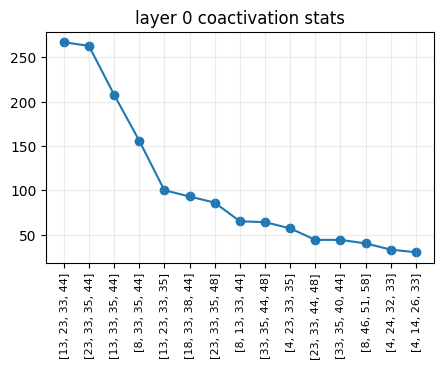

In [ ]:
plot_layer_coactivation_stats(0, 4)

In [ ]:
embs_subset_anatomy = all_embeddings_layer_0[all_embeddings_layer_0['task'] == 'anatomy']

In [ ]:
if (False):
    saved_embs_2d_layer_0 = show_layers_from_full_space(layers=[0], 
        plot_activation_stats=True, 
        suptitle="layer 0 embeddings without mean",
        embs_only=embs_subset_anatomy.iloc[:, 3:],
        embeddings_with_meta = embs_subset_anatomy,
    )
        # tsne_algo=umap.UMAP(),
        #custom_c=hdb.labels_)

In [ ]:
all_embeddings_layer_23 = parser.get_all_expert_embeddings(all_topics, [23])

anatomy !!!
conceptual_physics !!!
human_sexuality !!!
machine_learning !!!
management !!!
marketing !!!
nutrition !!!
philosophy !!!
us_foreign_policy !!!
world_religions !!!


In [ ]:
embs_subset_anatomy_23 = all_embeddings_layer_23[all_embeddings_layer_23['task'] == 'anatomy']

In [ ]:
if (False):
    saved_embs_2d_layer_23 = show_layers_from_full_space(layers=[23], 
        plot_activation_stats=True, 
        suptitle="layer 23 embeddings without mean",
        embs_only=embs_subset_anatomy_23.iloc[:, 3:],
        embeddings_with_meta = embs_subset_anatomy_23,
    )
    # tsne_algo=umap.UMAP(),
    #custom_c=hdb.labels_)

/glazkov-dev/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


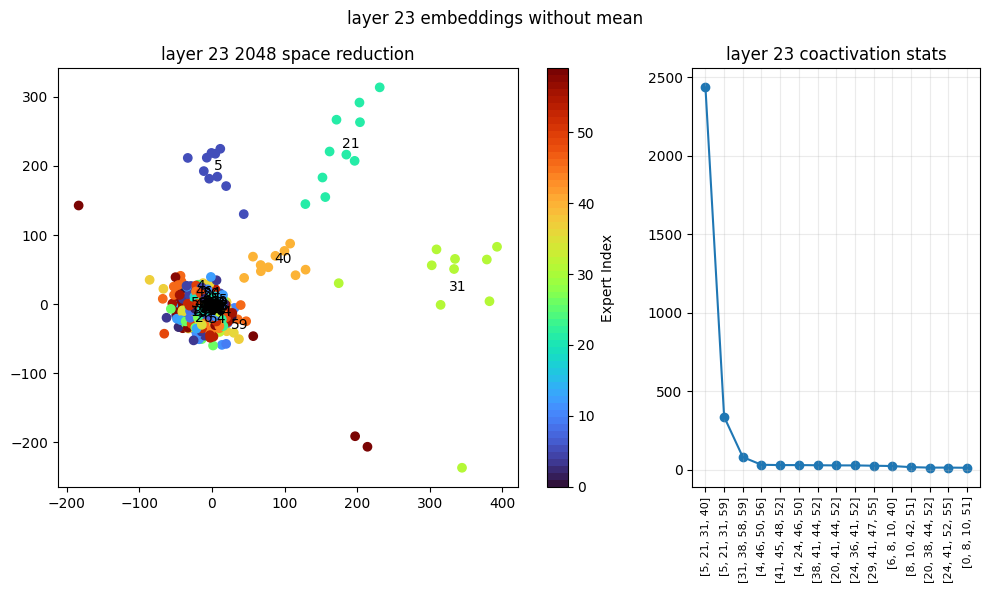

[array([[ 31.0419576 ,  -5.41789531],
        [-25.31822833, -21.18410938],
        [ -0.74585623,   9.91366699],
        ...,
        [  9.46788262, -11.28892103],
        [-14.05040946, -29.89091137],
        [ -6.0332699 ,  -8.82084676]], shape=(598, 2))]

In [ ]:
show_layers_from_full_space(layers=[23], 
    plot_activation_stats=True, 
    suptitle="layer 23 embeddings without mean",
    embs_only=embs_only_full,
    embeddings_with_meta = embeddings,
)

## Лучше обсчитывать на полных данных

In [ ]:
import sys
from pathlib import Path
import torch
sys.path.insert(0, str(Path.cwd().resolve().parents[1]))
from MoE_Optimization.common.clustering_utils import MMLUBatchGenerator


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch

#model, tokenizer = get_qwen(...)

MODEL = "Qwen/Qwen1.5-MoE-A2.7B"
DEVICE_MAP = {"": "cuda:0"}

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

tokenizer = AutoTokenizer.from_pretrained(MODEL, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL,
    trust_remote_code=True,
    device_map=DEVICE_MAP,
    dtype=torch.float16,
    quantization_config=quantization_config,
    cache_dir='../../.cache',
)


I0000 00:00:1778157973.214476  168777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778157973.290723  168777 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778157975.543768  168777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
from MoE_Optimization.common.clustering_utils import SELECTED_TASKS, convert_inputs_to_tokens
from MoE_Optimization.common.expert_clusterer import ExpertClusterer
import importlib
# importlib.reload(expert_clusterer)

gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)
example_inputs = convert_inputs_to_tokens(gen, tokenizer, model.device)
clusterer = ExpertClusterer(model, example_inputs)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Initialized MMLU batch generator with 5 subjects
Split: validation, Batch size: 16

📚 Loading subject 1/5: anatomy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 14 questions

📚 Loading subject 2/5: machine_learning


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 3/5: management


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 4/5: philosophy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 16 questions

📚 Loading subject 5/5: world_religions
  ✓ Created batch with 16 questions


In [ ]:
from MoE_Optimization.common.moe_utils import discover_moe_layers
layers = discover_moe_layers(model)
layers

[MoeHandle(layer_idx=0, moe=Qwen2MoeSparseMoeBlock(
   (gate): Linear4bit(in_features=2048, out_features=60, bias=False)
   (experts): ModuleList(
     (0-59): 60 x Qwen2MoeMLP(
       (gate_proj): Linear4bit(in_features=2048, out_features=1408, bias=False)
       (up_proj): Linear4bit(in_features=2048, out_features=1408, bias=False)
       (down_proj): Linear4bit(in_features=1408, out_features=2048, bias=False)
       (act_fn): SiLUActivation()
     )
   )
   (shared_expert): Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
     (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
     (act_fn): SiLUActivation()
   )
   (shared_expert_gate): Linear4bit(in_features=2048, out_features=1, bias=False)
 ), gate=Linear4bit(in_features=2048, out_features=60, bias=False), experts=ModuleList(
   (0-59): 60 x Qwen2MoeMLP(
     (gate_proj): Linear4bit(in_featu

In [ ]:
handles2clusters = clusterer.create_clusters_by_PI([layers[23]])

## FOR DEBUG

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])


In [ ]:
name2activations['model.layers.23.mlp.gate'].shape

torch.Size([2662, 60])

In [ ]:
name2activations = clusterer.get_activations([layers[23]], attach_to_gate_layer=True, attach_to_expert_layer=False)


In [ ]:
name2activations['model.layers.23.mlp.gate']

[tensor([[ -5.2578,  -4.4727,  -3.8340,  ...,  -5.2383,  -3.7090,  -3.8320],
         [ -3.7402,  -6.0430,  -6.1562,  ...,  -3.8633,  -5.8594,  -4.0000],
         [ -3.4609,  -5.3281,  -4.4688,  ...,  -3.7539,  -5.7266,  -4.2422],
         ...,
         [ -6.7539, -10.5859, -10.2734,  ...,  -6.9453,  -8.4219,  -6.2109],
         [ -6.6484, -10.5703,  -9.8984,  ...,  -6.9492,  -8.3672,  -5.9141],
         [ -6.5859, -10.5234, -10.1016,  ...,  -6.8867,  -8.4062,  -6.0156]],
        device='cuda:0', dtype=torch.float16),
 tensor([[-5.2539, -4.4688, -3.8301,  ..., -5.2344, -3.7070, -3.8281],
         [-3.7402, -6.0391, -6.1562,  ..., -3.8633, -5.8594, -4.0039],
         [-3.4629, -5.3242, -4.4648,  ..., -3.7559, -5.7266, -4.2422],
         ...,
         [-4.5195, -8.0234, -7.6641,  ..., -5.5664, -5.5664, -4.4531],
         [-4.5859, -8.0859, -7.6914,  ..., -5.6328, -5.5938, -4.5000],
         [-4.5352, -8.0000, -7.6836,  ..., -5.6016, -5.5312, -4.5078]],
        device='cuda:0', dtype=torc

In [ ]:
# ExpertLoggerDataConverter.compute_PI_matrix(clusterer.model.num_experts, 
#                                         name2activations.items()[0], 
#                                         k = layers[23].gate.top_k)

In [ ]:
handles2clusters[23]

[[33, 9, 10],
 [27, 20, 8],
 [2, 18, 12],
 [43, 59],
 [30, 49],
 [47, 19],
 [14, 7],
 [45, 46, 36],
 [28, 48],
 [29, 1],
 [41, 11],
 [3, 37],
 [24, 26],
 [22, 56],
 [53, 32],
 [51, 35],
 [44, 40],
 [57, 23],
 [15, 21],
 [39, 16],
 [4, 42],
 [31, 34],
 [50, 38],
 [25, 13],
 [54, 52],
 [5, 6],
 [0, 17],
 [55, 58]]

In [ ]:
embeddings.shape

(14277, 2051)

/glazkov-dev/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


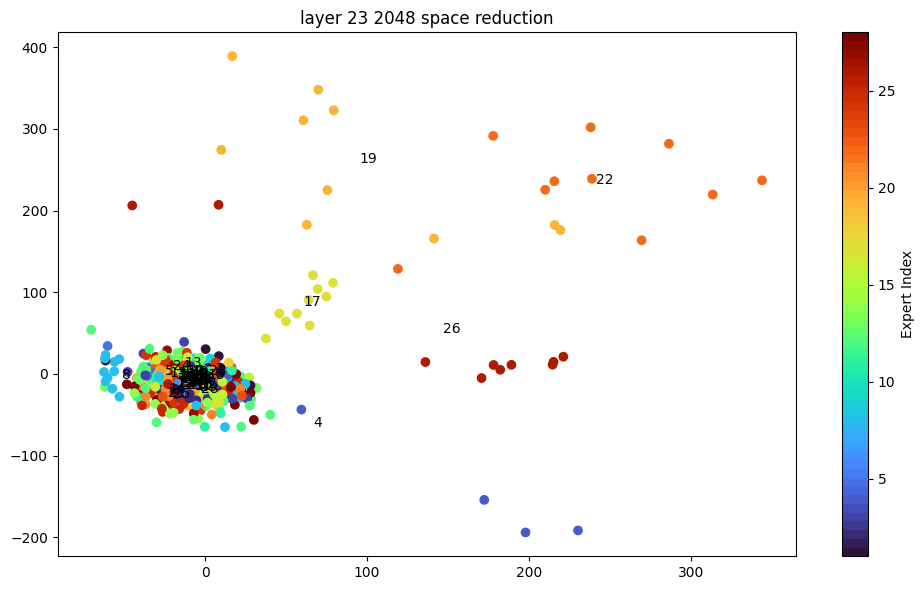

[array([[  0.22355337,  30.32874297],
        [  0.91029651, -26.50616088],
        [  5.29215886,   3.775766  ],
        ...,
        [ 10.51332212,  -9.66837815],
        [-30.85896613, -15.8323395 ],
        [ -5.71709472, -10.52684146]], shape=(598, 2))]

In [ ]:
custom_c_23 = clusters_to_custom_c(handles2clusters[23], embeddings_with_meta=embeddings[embeddings['layer']==23])
show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)

Видно раскраску, сократилась в два раза по цветам. Видно, что стратегия min PI приводит к тому, что удалённые кластеры остаются удалены. (так модель будет иметь возможность выбирать из разных независимых экспертов)

Можно попробовать стратегию max PI

In [ ]:
from MoE_Optimization.common.expert_logger_data_converter import ExpertLoggerDataConverter
from MoE_Optimization.common.expert_matcher import ExpertMatcher


name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True)

/glazkov-dev/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


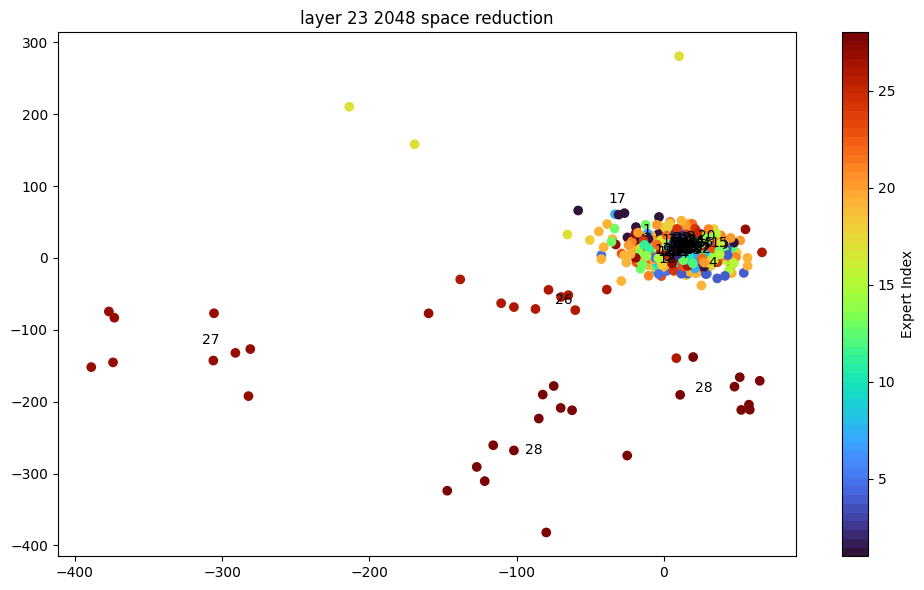

[array([[ 45.83382887,  -9.95681581],
        [ 26.91105542,  18.32796614],
        [ -3.57892152,  -6.56368181],
        ...,
        [ 19.78876387,  -7.58959384],
        [-11.89490786,   2.7386151 ],
        [  9.43087215,   5.27533413]], shape=(598, 2))]

In [ ]:
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
show_layers_from_full_space(layers=[23], custom_c=custom_c_23, embeddings_with_meta=embeddings, embs_only=embs_only_full)

Кластера разглядывать пока всё ещё не удобно. Введём метрики.

calinski-harabasz - для общей оценки результата кластеризации, межгрупповая дисперсия/внутригрупповая
silhouette score - для всех точек между кластерами мерит среднюю удалённость, чем выше тем лучше, точки ближе к своим кластерам чем к чужим.

До этого мерили кластеризацию на mixtral только сугубо для отдельных пар экспертов. То есть смотрели как два облака хорошо разделяются и как это кореллирует с популярностью их выбора.
На глаз лучше всего оказалась метрика calinski-harabarsz. Остальные плохо кореллируют.

Теперь будем использовать метрики для оценки всей кластеризации в целом.

In [ ]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, Birch, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def evaluate_clustering_metrics(X, labels):
    # Filter out noise points (-1) for metrics that don't handle them
    mask = labels != -1
    if mask.sum() > 1:
        X_clean = X[mask]
        labels_clean = labels[mask]
        
        metrics = {
            'silhouette': silhouette_score(X_clean, labels_clean),
            'calinski_harabasz': calinski_harabasz_score(X_clean, labels_clean),
            'davies_bouldin': davies_bouldin_score(X_clean, labels_clean),
            'n_clusters': len(set(labels_clean)),
            'noise_points': (labels == -1).sum()
        }
        return metrics
    return None

In [ ]:
history.__len__()

27

In [ ]:
# sensitive to scale, other metrics!
# from sklearn.preprocessing import StandardScaler
# X = embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64)
# X = StandardScaler().fit_transform(X)
# evaluate_clustering_metrics(X, embeddings[embeddings['layer'] == 23]['expert'])

In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231335,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

Maximize PI for comparsion

In [ ]:
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), custom_c_23)

{'silhouette': -0.15434899751875505,
 'calinski_harabasz': 21.741109345560044,
 'davies_bouldin': 2.6587246723495688,
 'n_clusters': 28,
 'noise_points': np.int64(0)}

Minimize PI

In [ ]:
handles2clusters = clusterer.create_clusters_by_PI([layers[23]])

In [ ]:
clusters = handles2clusters.items().__iter__().__next__()[1]
custom_c_23 = clusters_to_custom_c(clusters, embeddings_with_meta=embeddings[embeddings['layer']==23])
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), custom_c_23)

{'silhouette': -0.19756064796032108,
 'calinski_harabasz': 14.141407811992659,
 'davies_bouldin': 2.992123532516156,
 'n_clusters': 28,
 'noise_points': np.int64(0)}

In [ ]:
a = [6]
a.insert(0, 5)
a

[5, 6]

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score



def labels_from_clusters(clusters, row_experts):
    '''transforms labels to merged labels'''
    expert_to_cluster = {}
    for cluster_id, cluster in enumerate(clusters):
        for expert in cluster:
            expert_to_cluster[expert] = cluster_id
    return np.asarray([expert_to_cluster.get(expert, -1) for expert in row_experts], dtype=np.int64)



def build_history_metrics_df(history, X, row_experts):
    rows = []

    for step, entry in enumerate(history):
        clusters = entry.get("all_clusters", entry.get("clusters"))
        if clusters is None or len(clusters) < 2:
            continue

        labels = labels_from_clusters(clusters, row_experts) #insted of series of expert indices makes indices of clusters
        valid_mask = labels >= 0
        X_step = X[valid_mask]
        labels_step = labels[valid_mask]

        if X_step.shape[0] < 2 or np.unique(labels_step).size < 2:
            continue

        row = {
            "step": step,
            "n_clusters": len(clusters),
            "metric_of_split_cluster": entry.get("metric_of_split_cluster", np.nan),
        }
        row.update({
            key: value
            for key, value in entry.items()
            if key.startswith("total_") and key.endswith("_after_split")
        })

        try:
            row["silhouette"] = silhouette_score(X_step, labels_step)
        except Exception:
            row["silhouette"] = np.nan

        try:
            row["calinski_harabasz"] = calinski_harabasz_score(X_step, labels_step)
        except Exception:
            row["calinski_harabasz"] = np.nan

        try:
            row["davies_bouldin"] = davies_bouldin_score(X_step, labels_step)
        except Exception:
            row["davies_bouldin"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
display(history_df)
print("history_df length:", len(history_df))

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,2,0.007912,0.011056,0.041297,23.642207,2.978415
1,1,3,0.009274,0.013967,-0.112196,36.317319,5.237851
2,2,4,0.012837,0.017094,-0.120361,24.515601,5.086365
3,3,5,0.014048,0.018266,-0.120205,18.515942,4.769392
4,4,6,0.013967,0.018623,-0.181144,14.982690,4.445465
5,5,7,0.017012,0.020498,-0.188449,12.702357,4.505327
6,6,8,0.013980,0.021137,-0.209084,10.920089,4.285297
7,7,9,0.017838,0.021198,-0.218238,9.577590,4.085182
8,8,10,0.018565,0.025728,-0.179975,22.729785,4.044188
9,9,11,0.014579,0.027303,-0.174500,20.864268,3.967862


history_df length: 27


NOTE: history now from Maximize PI (if metric grows)

In [ ]:
import matplotlib.pyplot as plt
import math


def plot_history_metrics(history_df, suptitle=""):
    if history_df.empty:
        print("history_df is empty")
        return

    base_columns = [
        ("n_clusters", "Number of clusters"),
        ("metric_of_split_cluster", "metric_of_split_cluster"),
        ("silhouette", "Silhouette"),
        ("calinski_harabasz", "Calinski-Harabasz"),
        ("davies_bouldin", "Davies-Bouldin"),
    ]
    total_columns = [
        (column, column)
        for column in history_df.columns
        if column.startswith("total_") and column.endswith("_after_split")
    ]
    plot_columns = base_columns + total_columns

    if not plot_columns:
        print("No metric columns found")
        return

    n_plots = len(plot_columns)
    n_cols = 3 if n_plots > 1 else 1
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    
    fig.suptitle(suptitle)

    for ax, (column, title) in zip(axes, plot_columns):
        ax.plot(history_df["step"], history_df[column], marker="o", linewidth=2)
        ax.set_title(title)
        ax.set_xlabel("step")
        ax.grid(True, alpha=0.3)

    for ax in axes[n_plots:]:
        ax.axis("off")

    for ax in axes[:n_plots]:
        ax.set_xlim(history_df["step"].min(), history_df["step"].max())

    fig.tight_layout()
    plt.show()

Minimize PI

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })

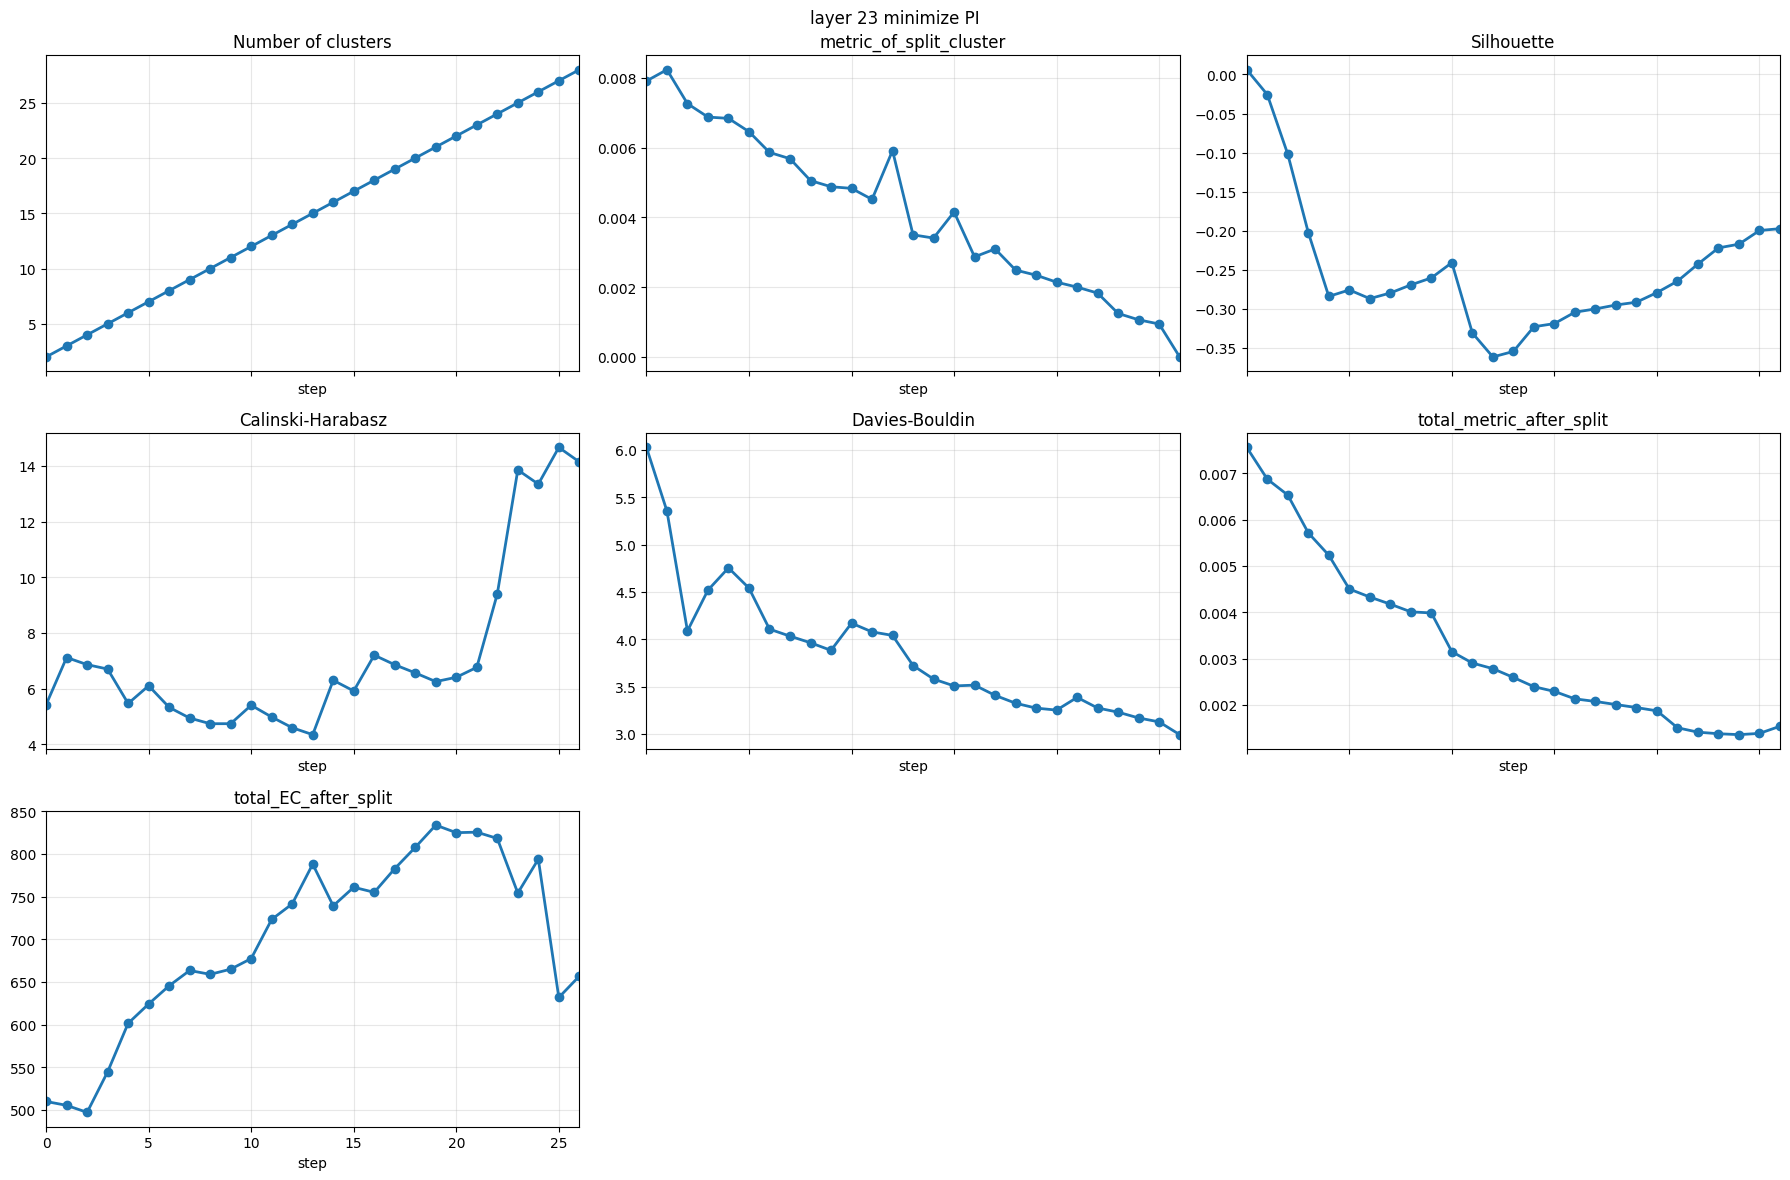

In [ ]:
layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df, 'layer 23 minimize PI')

lets try on full embeddings (not mean) for layer 23

In [ ]:
all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1)

/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,-4.625000,-1.360352,-3.408203,0.334961,-2.513672,-2.847656,-2.134766,-1.212891,-2.257812,-1.765625,...,-0.153687,-0.975586,0.306641,-2.777344,-0.522461,-0.084900,1.731445,1.327148,0.563477,-2.210938
1,-0.237061,1.125000,-0.273193,1.958008,-3.373047,2.222656,-1.642578,1.476562,0.314941,-3.109375,...,-3.000000,1.572266,0.417725,3.761719,-0.005192,-0.315430,0.451172,1.512695,-1.270508,-2.003906
2,-1.536133,0.137329,-0.521484,0.537109,-0.519531,0.052765,-1.004883,2.753906,-0.154541,-2.533203,...,-1.642578,1.944336,-1.458984,2.623047,1.006836,1.344727,0.810059,0.604980,-3.996094,0.832031
3,0.906738,-0.316895,0.027145,0.142700,-0.253174,-1.541992,-0.987305,0.486328,-0.975586,1.989258,...,0.720703,2.375000,-1.658203,1.529297,-2.146484,-2.498047,1.254883,-0.478271,-0.506836,-1.825195
4,0.570312,-0.187378,-0.837402,2.966797,-1.634766,2.457031,-2.224609,2.214844,1.683594,-0.506836,...,0.545898,2.191406,-0.540527,-0.088928,0.703613,1.141602,-1.704102,4.703125,-1.902344,2.769531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21915,0.126221,1.038086,0.808105,0.096558,0.473145,0.354736,-0.303467,0.295654,-0.557129,-0.660645,...,0.257324,-0.667480,-1.002930,0.346924,-0.699219,-0.604004,0.244507,-0.583496,-0.067139,-0.265381
21916,0.268311,0.256348,0.584961,1.046875,0.116760,0.000642,-0.143188,0.353760,-0.063232,0.115417,...,0.753418,0.867188,-0.475342,0.623535,0.172974,0.001497,0.210449,-0.234619,0.219360,0.255371
21917,-0.684082,0.169556,0.899902,-1.037109,-0.789551,1.132812,-0.950684,0.335449,0.328613,-1.533203,...,-0.061066,0.653320,-0.633301,-0.635742,-1.341797,0.711426,0.117981,-0.730957,0.060760,-0.428955
21918,-0.061371,1.128906,1.092773,-0.604004,1.100586,0.212891,-0.065430,-1.112305,0.421631,0.102356,...,-0.422363,0.253662,0.183105,-0.704590,0.150757,0.989746,-0.641602,0.608398,-0.094055,0.150391


In [ ]:
too_long_compute=True
if (too_long_compute != True):
    name2activations = clusterer._get_activations_from_gate([layers[23]])
    gate_activations = name2activations.items().__iter__().__next__()[1]
    target_layer = layers[23]
    gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                                gate_activations, 
                                                                k = target_layer.moe.top_k)
    gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                                gate_activations, 
                                                                k = target_layer.moe.top_k)
    clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                            maximize_metric=False, 
                                                            log_history=True,
                                                            other_matrices_for_stats={
                                                                'EC': gate_EC_matrix
                                                            })

    layer_id = 23
    layer_mask = all_embeddings_layer_23["layer"].eq(layer_id)
    X_layer = all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1).loc[layer_mask].to_numpy(dtype=np.float64)
    row_experts = all_embeddings_layer_23.loc[layer_mask, "expert"].to_numpy()

    history_df = build_history_metrics_df(history, X_layer, row_experts)
    plot_history_metrics(history_df, 'layer 23 minimize PI')

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[11]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[11]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })

In [ ]:
all_embeddings_layer_23.drop(["expert", "task", "layer"], axis=1)

/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,-4.625000,-1.360352,-3.408203,0.334961,-2.513672,-2.847656,-2.134766,-1.212891,-2.257812,-1.765625,...,-0.153687,-0.975586,0.306641,-2.777344,-0.522461,-0.084900,1.731445,1.327148,0.563477,-2.210938
1,-0.237061,1.125000,-0.273193,1.958008,-3.373047,2.222656,-1.642578,1.476562,0.314941,-3.109375,...,-3.000000,1.572266,0.417725,3.761719,-0.005192,-0.315430,0.451172,1.512695,-1.270508,-2.003906
2,-1.536133,0.137329,-0.521484,0.537109,-0.519531,0.052765,-1.004883,2.753906,-0.154541,-2.533203,...,-1.642578,1.944336,-1.458984,2.623047,1.006836,1.344727,0.810059,0.604980,-3.996094,0.832031
3,0.906738,-0.316895,0.027145,0.142700,-0.253174,-1.541992,-0.987305,0.486328,-0.975586,1.989258,...,0.720703,2.375000,-1.658203,1.529297,-2.146484,-2.498047,1.254883,-0.478271,-0.506836,-1.825195
4,0.570312,-0.187378,-0.837402,2.966797,-1.634766,2.457031,-2.224609,2.214844,1.683594,-0.506836,...,0.545898,2.191406,-0.540527,-0.088928,0.703613,1.141602,-1.704102,4.703125,-1.902344,2.769531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21915,0.126221,1.038086,0.808105,0.096558,0.473145,0.354736,-0.303467,0.295654,-0.557129,-0.660645,...,0.257324,-0.667480,-1.002930,0.346924,-0.699219,-0.604004,0.244507,-0.583496,-0.067139,-0.265381
21916,0.268311,0.256348,0.584961,1.046875,0.116760,0.000642,-0.143188,0.353760,-0.063232,0.115417,...,0.753418,0.867188,-0.475342,0.623535,0.172974,0.001497,0.210449,-0.234619,0.219360,0.255371
21917,-0.684082,0.169556,0.899902,-1.037109,-0.789551,1.132812,-0.950684,0.335449,0.328613,-1.533203,...,-0.061066,0.653320,-0.633301,-0.635742,-1.341797,0.711426,0.117981,-0.730957,0.060760,-0.428955
21918,-0.061371,1.128906,1.092773,-0.604004,1.100586,0.212891,-0.065430,-1.112305,0.421631,0.102356,...,-0.422363,0.253662,0.183105,-0.704590,0.150757,0.989746,-0.641602,0.608398,-0.094055,0.150391


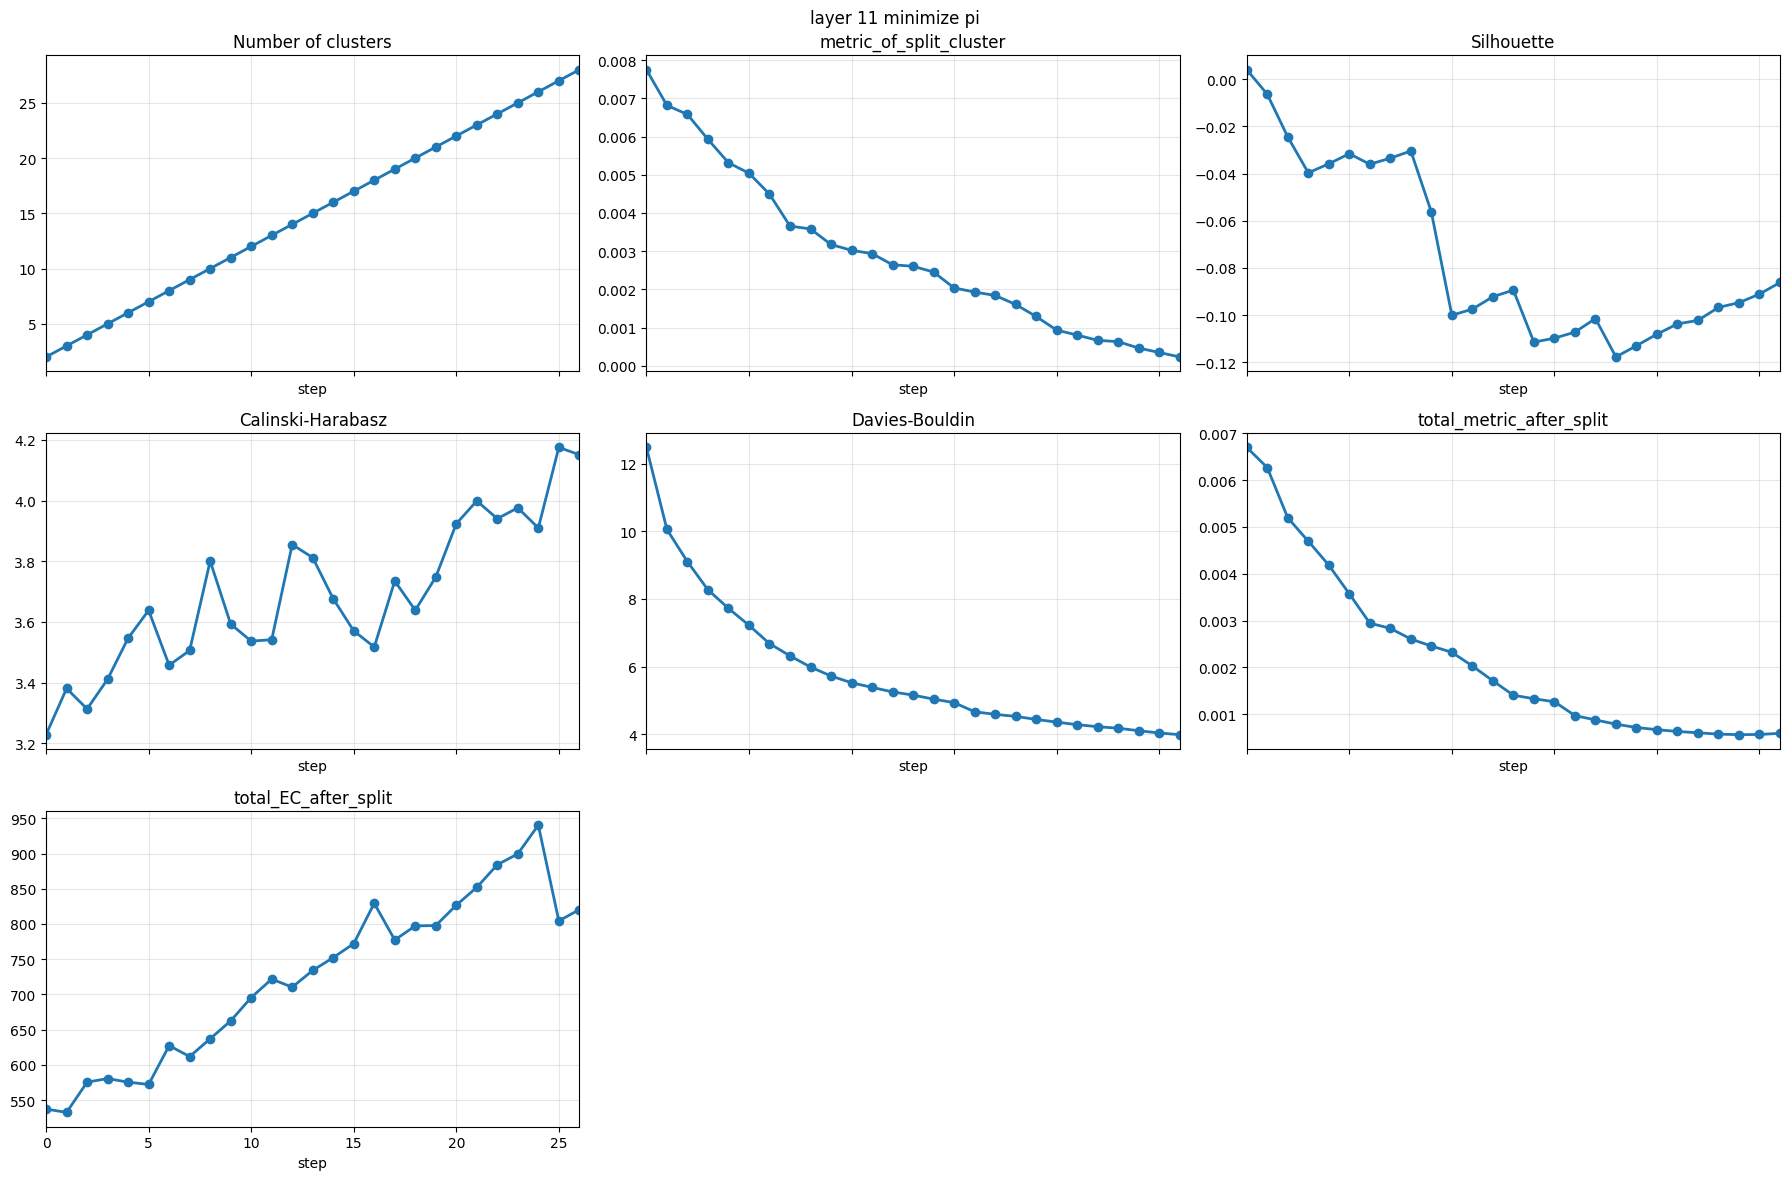

In [ ]:
layer_id = 11
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df, 'layer 11 minimize pi')

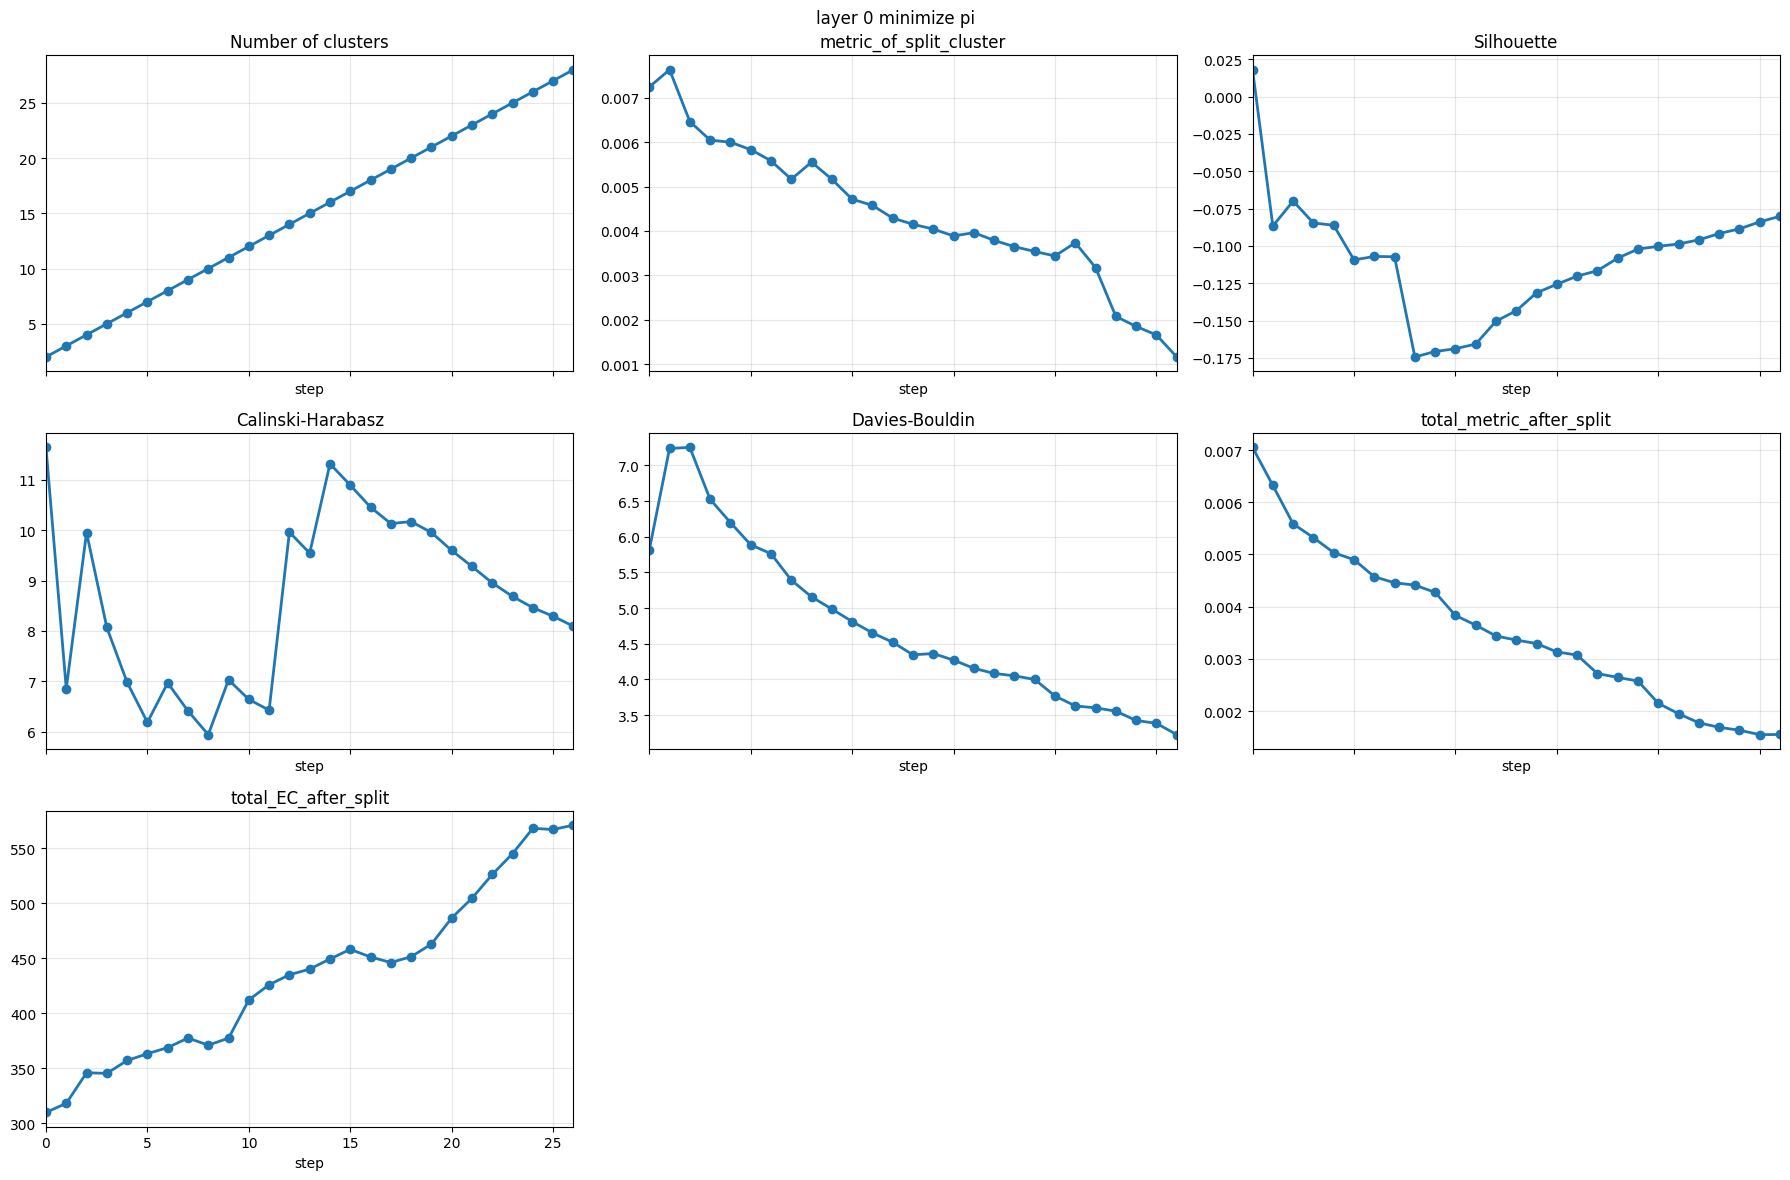

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_0 = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_0, 'layer 0 minimize pi')

max ec

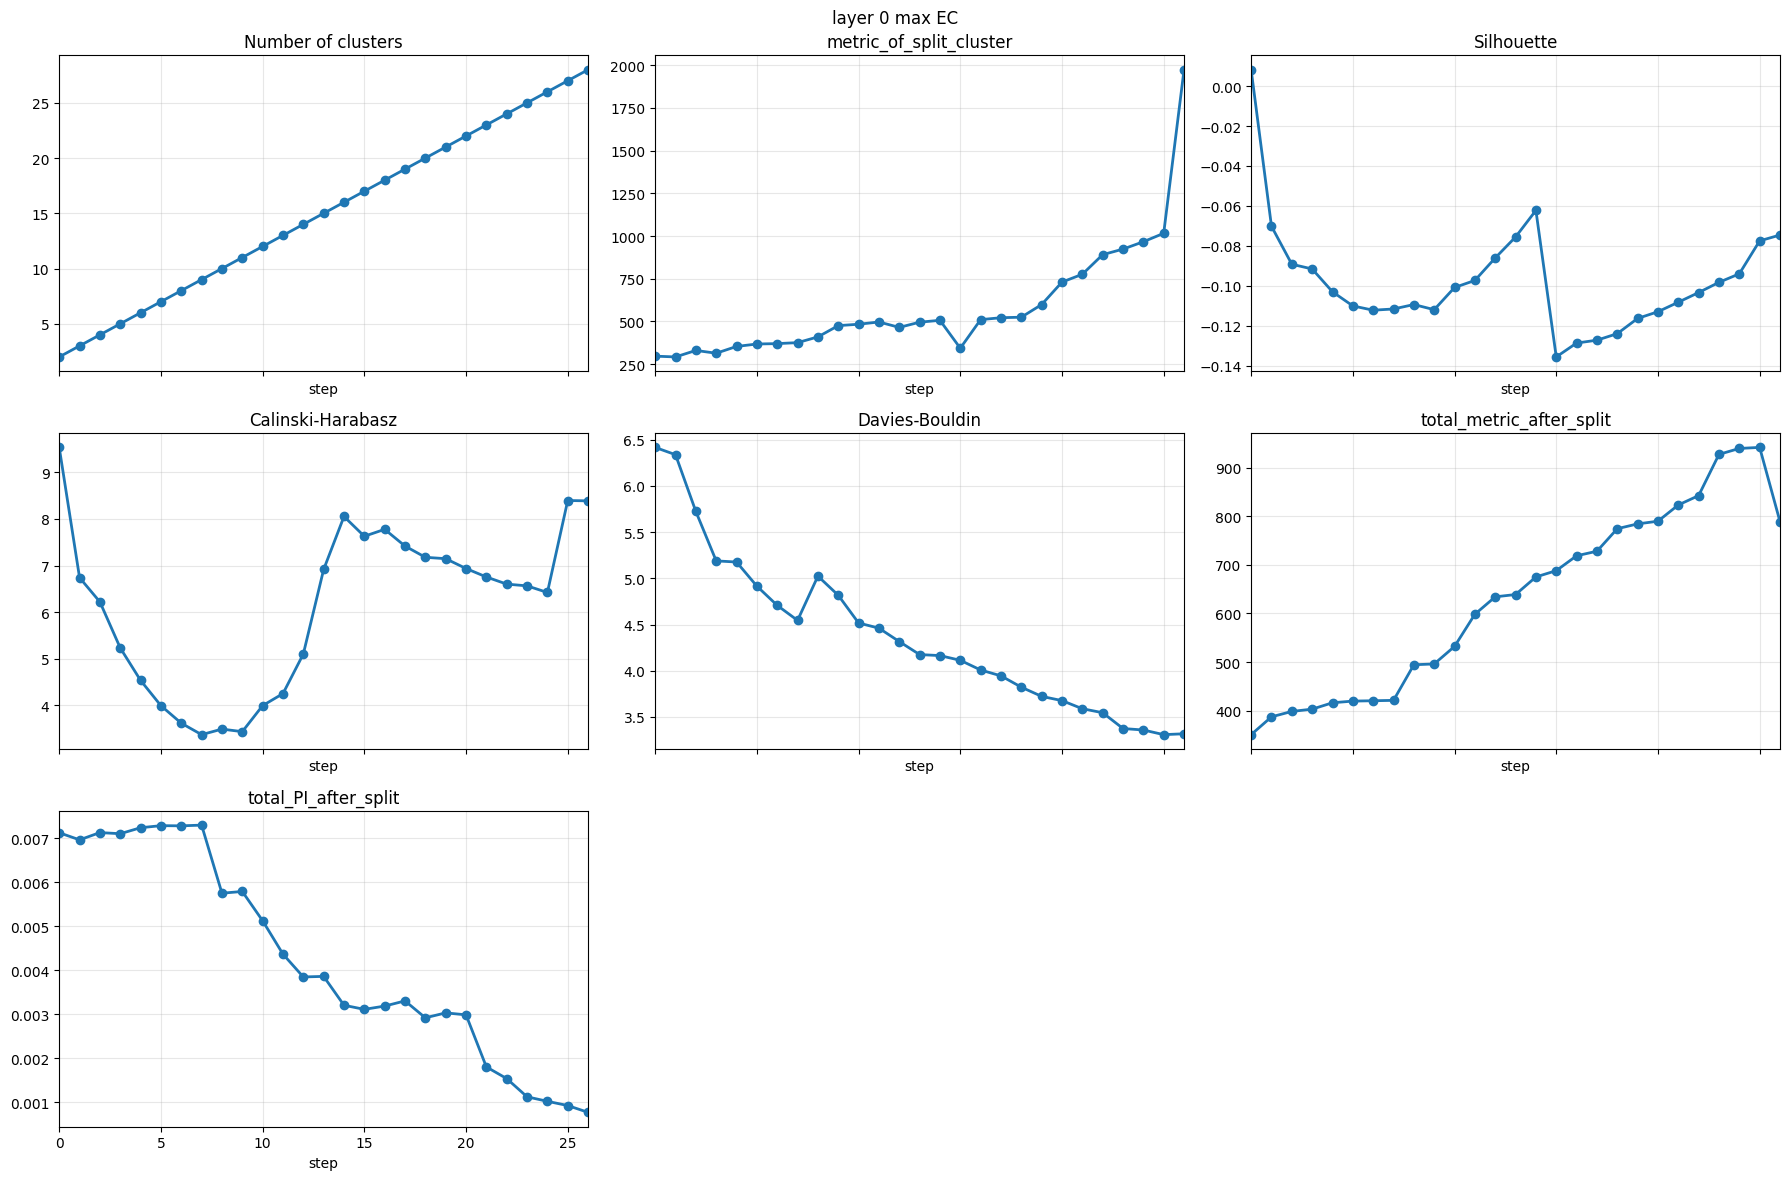

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_0_max_ec = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_0_max_ec, 'layer 0 max EC')

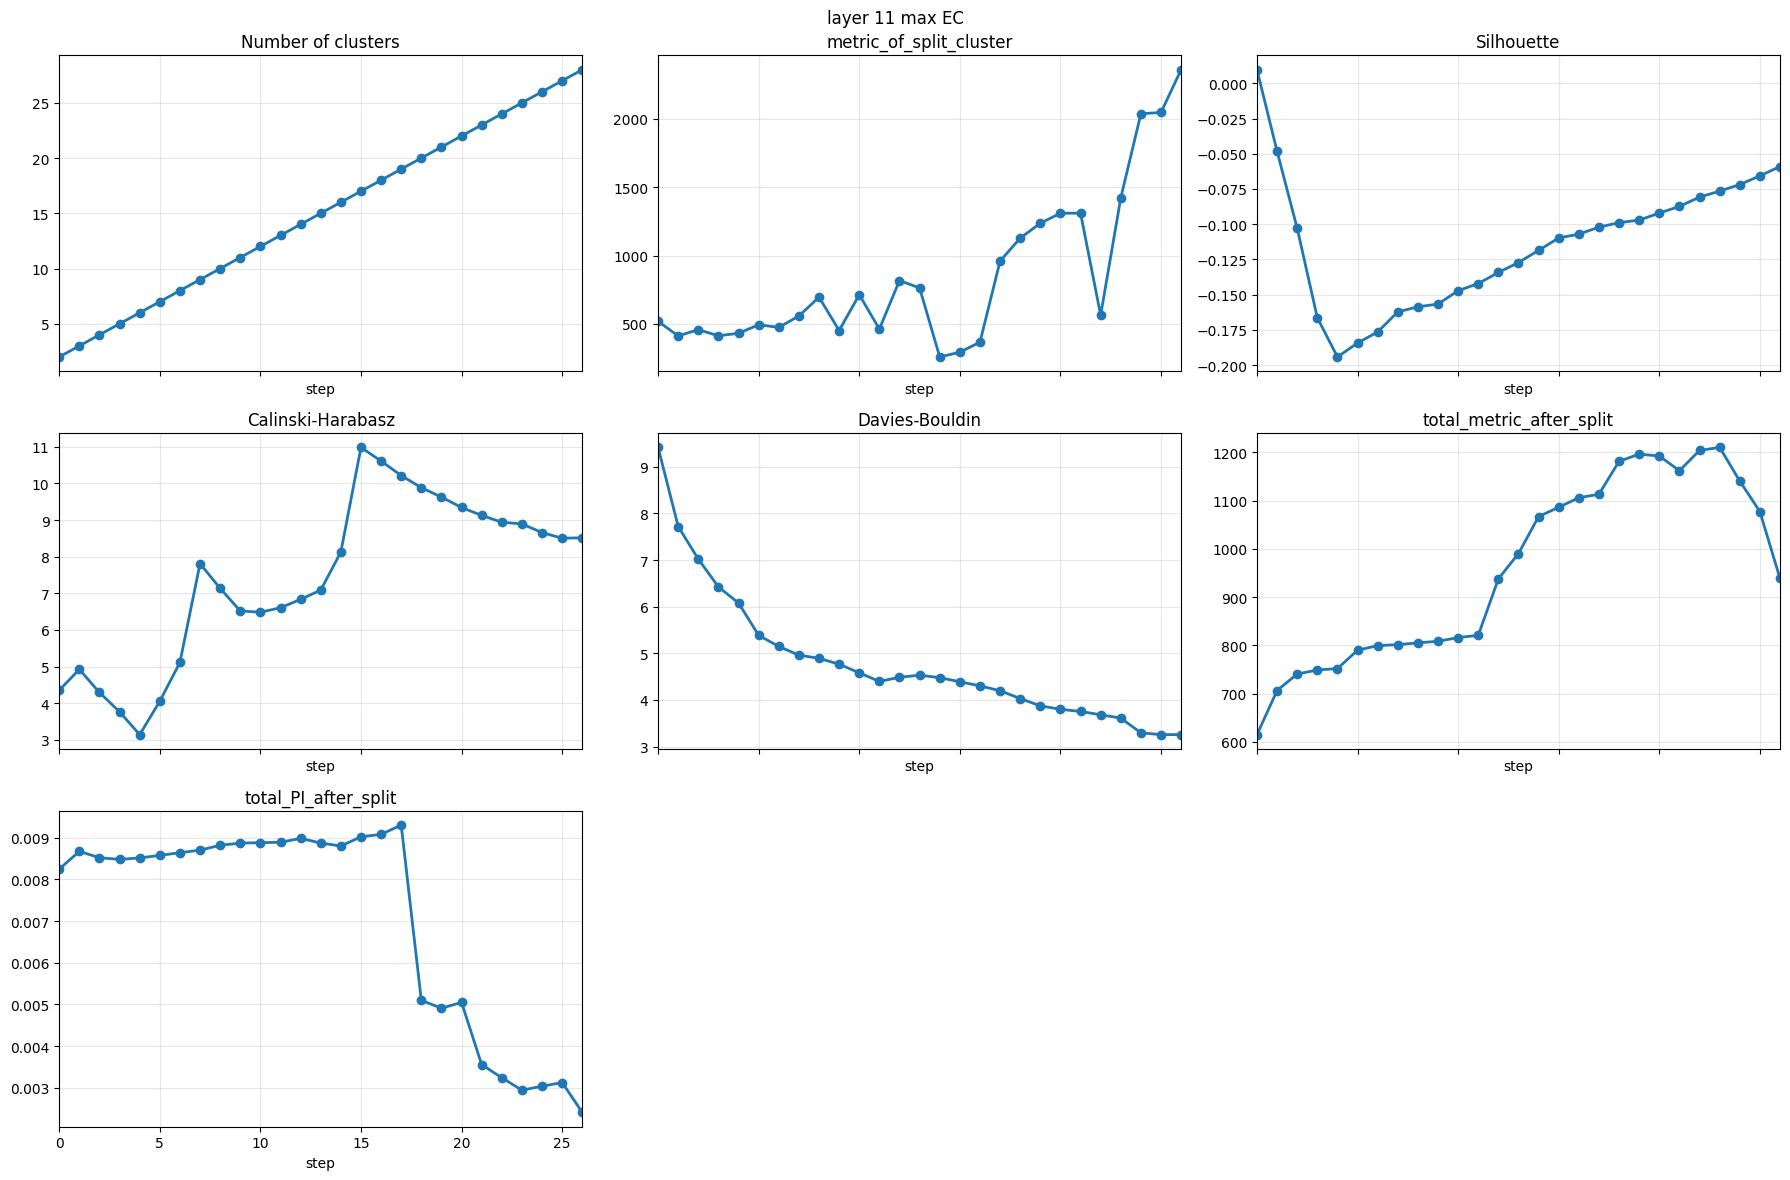

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[11]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[11]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_11_max_ec = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_11_max_ec, 'layer 11 max EC')

In [ ]:
##type here

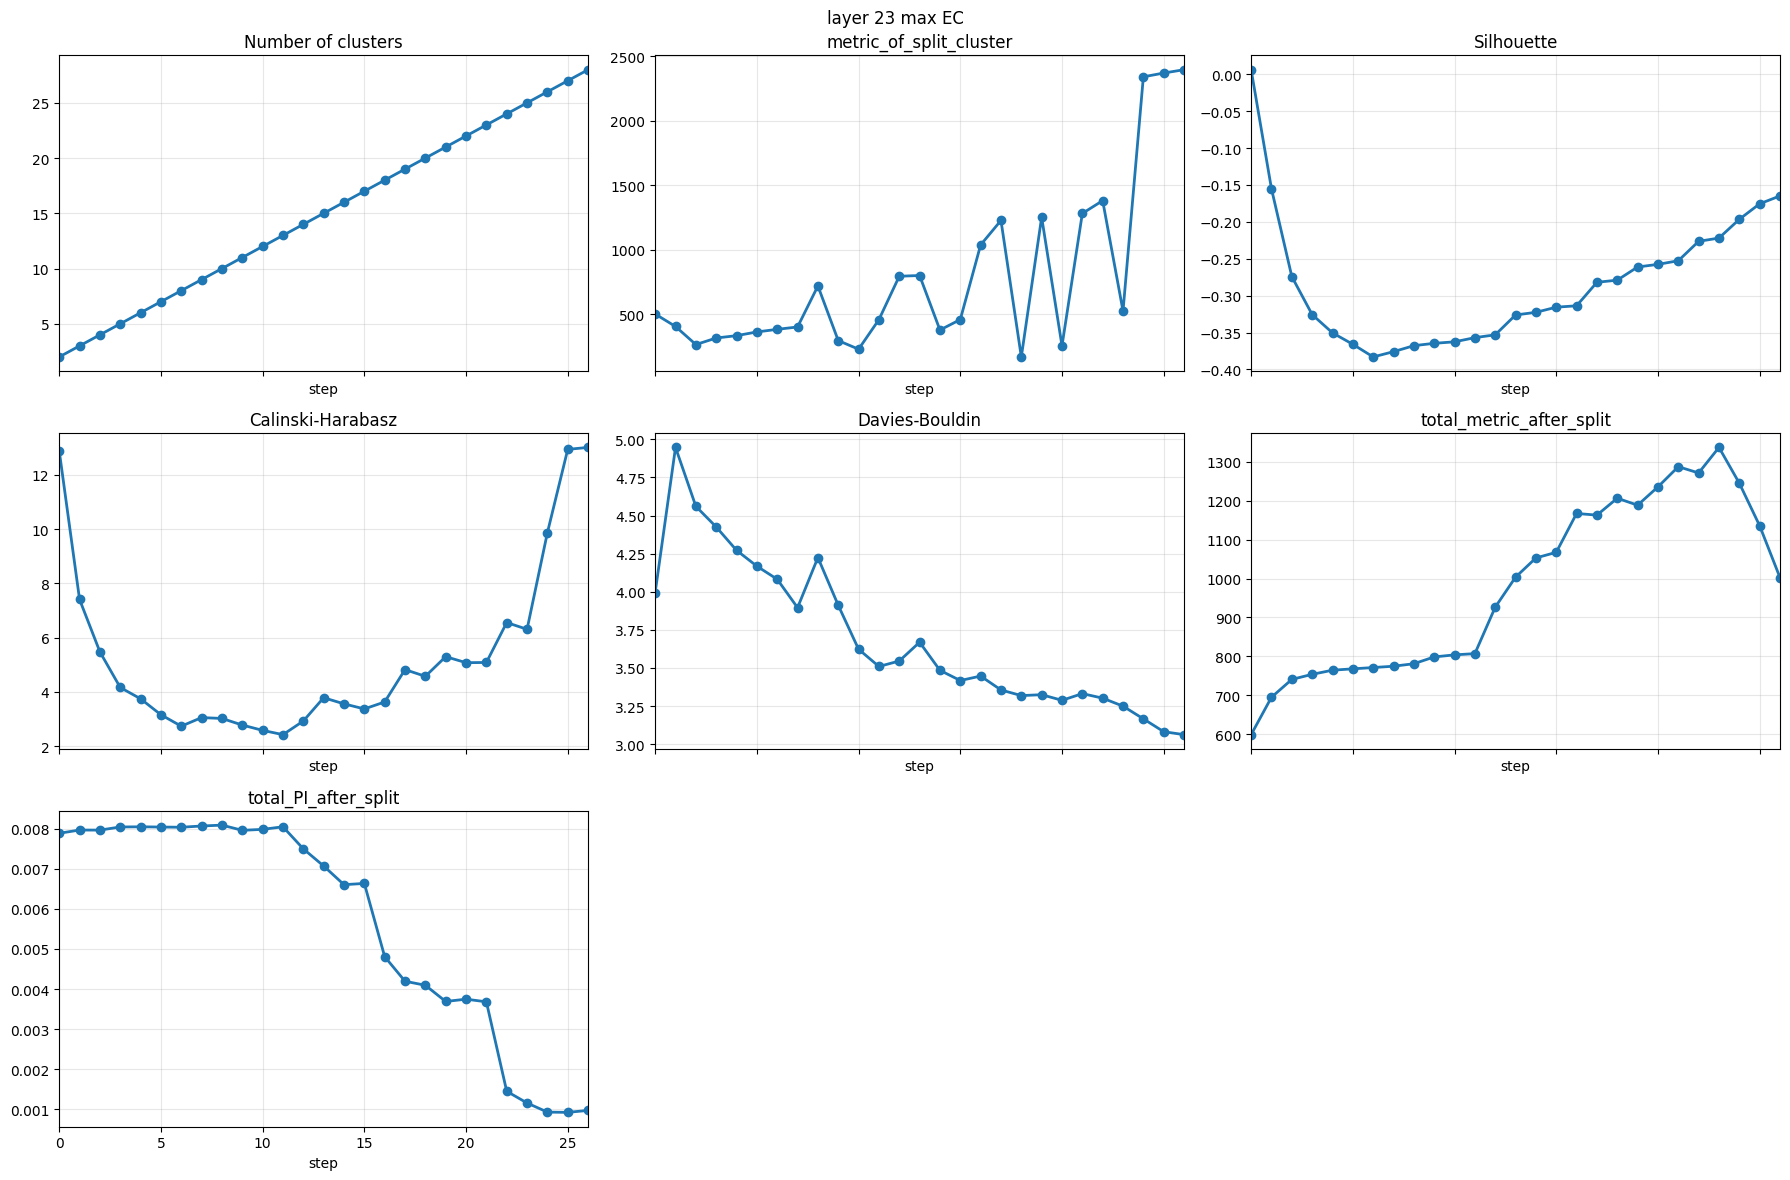

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_EC_matrix, 
                                                        maximize_metric=True, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'PI': gate_PI_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_23_max_EC = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_23_max_EC, 'layer 23 max EC')

In [ ]:
##add method here

In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231335,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

In [ ]:
evaluate_clustering_metrics(all_embeddings_layer_23[all_embeddings_layer_23['layer'] == 23].drop(['expert', 'layer', 'task'], axis=1).to_numpy(dtype=np.float64), all_embeddings_layer_23[all_embeddings_layer_23['layer'] == 23]['expert'])

{'silhouette': -0.007009798020605495,
 'calinski_harabasz': 575.3535266960276,
 'davies_bouldin': 4.89159101902743,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

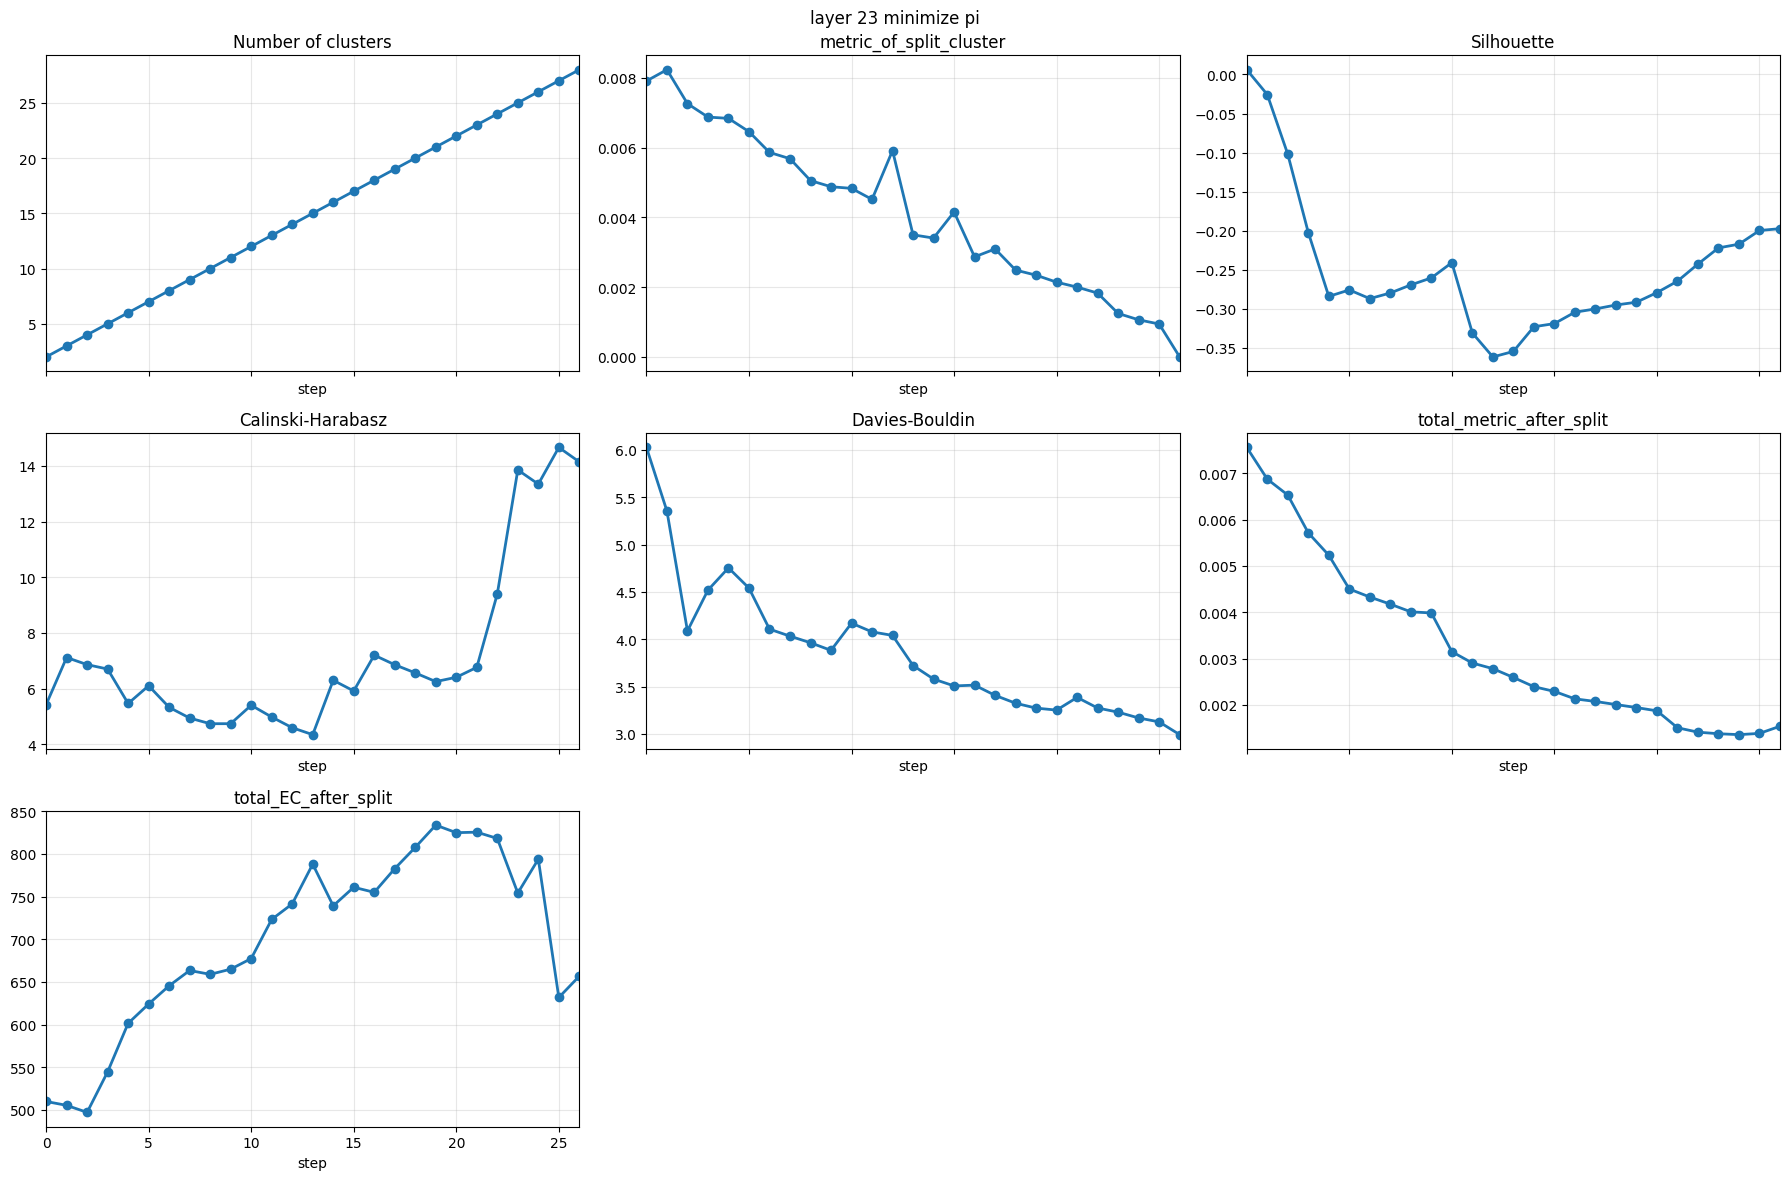

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df_23 = build_history_metrics_df(history, X_layer, row_experts)
plot_history_metrics(history_df_23, 'layer 23 minimize pi')

In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 0].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 0]['expert'])

{'silhouette': 0.017782165303674418,
 'calinski_harabasz': 14.734466901132762,
 'davies_bouldin': 2.3535113628948667,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

In [ ]:
history_df

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,2,0.007751,0.006698,537.296139,0.003974,3.228047,12.478773
1,1,3,0.006817,0.006267,532.668907,-0.006430,3.380337,10.051739
2,2,4,0.006579,0.005194,575.581222,-0.024513,3.312822,9.099099
3,3,5,0.005927,0.004695,580.623701,-0.039697,3.411046,8.266915
4,4,6,0.005314,0.004183,575.497649,-0.035887,3.546384,7.720378
5,5,7,0.005042,0.003571,572.301101,-0.031608,3.637954,7.219257
6,6,8,0.004493,0.002944,627.363715,-0.036072,3.456924,6.677599
7,7,9,0.003657,0.002833,611.872641,-0.033500,3.505808,6.315204
8,8,10,0.003582,0.002605,637.127026,-0.030448,3.800495,5.984637
9,9,11,0.003175,0.002456,662.466068,-0.056298,3.592648,5.719826


Слишком много пересекающихся факторов, которые пока не понятно как разделить. У кластеров есть: 1) плотность 2) расстояние до центра 3) расстояние до других кластеров 4) угол 5) размер или вытянутость 6) подпространство? принципал углы?

Помимо этого в статистику не понятно полностью как они берутся. Да, первыми идут самые удалённые и самые "разнородные", но что можно сказать про всех остальных - сложно.

Поэтому и разбиение основанное на популярности будет хорошо работать только для топ кластеров-экспертов. Как объединять остальных - не ясно.
Не была найдена чёткая корелляция между миром (метриками) популярности и метриками кластеров.

И последнее: метрики вообще могут ничего не показывать, так как реальный результат - это прогон модели, а не то, как расположены кластеры.

На завтра: добавить на выбор какую метрику использовать кроме PI (написать разные методы)
Добавить критерии остановки (тоже на выбор можно) + выбрать перемножение ec*pi или совместную метрику. Выбрать метрику локтя.


1) методы pi и ec
2) остановки pi и ec 
3) перемножение pi и ec
4) фронт pi
5) кластеризацие снизу, спаривание

In [ ]:
import numpy as np
from typing import Optional

from MoE_Optimization.common.clustering_utils import _weighted_average_cluster_metric


def find_by_agglomerative_clustering(
    adjacency_matrix_of_experts,
    maximize_metric=False,
    log_history=False,
    other_matrices_for_stats: Optional[dict[str, np.ndarray]] = None,
):
    '''
    Greedy matching over all edges.

    Build a queue of all expert pairs, sort it by PI, and then keep selecting
    edges whose endpoints are still unused. The result is a set of disjoint
    pairs plus singleton leftovers.

    Signature intentionally matches find_by_dividive_clustering.
    '''
    if adjacency_matrix_of_experts.ndim != 2 or adjacency_matrix_of_experts.shape[0] != adjacency_matrix_of_experts.shape[1]:
        raise ValueError('adjacency_matrix_of_experts must be a square matrix')

    score_mat = np.asarray(adjacency_matrix_of_experts, dtype=np.float64)
    n_experts = score_mat.shape[0]

    if n_experts == 0:
        return [], []
    if n_experts == 1:
        return [[0]], []

    edge_queue = [
        (float(score_mat[i, j]), i, j)
        for i in range(n_experts)
        for j in range(i + 1, n_experts)
    ]

    if maximize_metric:
        edge_queue.sort(key=lambda item: (-item[0], item[1], item[2]))
    else:
        edge_queue.sort(key=lambda item: (item[0], item[1], item[2]))

    used_vertices = set()
    clusters = []
    history = []

    for score, i, j in edge_queue:
        if i in used_vertices or j in used_vertices:
            continue

        used_vertices.add(i)
        used_vertices.add(j)
        clusters.append([i, j])

    if log_history:
        step_dict = {
            'step': len(history) + 1,
            'all_clusters': clusters,
            "total_metric_after_split": _weighted_average_cluster_metric(adjacency_matrix_of_experts, clusters),

        }
        if other_matrices_for_stats is not None:
            for key in other_matrices_for_stats.keys():
                step_dict[f'total_{key}_after_split'] = _weighted_average_cluster_metric(other_matrices_for_stats[key], clusters)
        history.append(step_dict)

    return clusters, history


In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.000175,1037.994444,-0.155515,13.27465,2.80511


compare with dividive and initial

In [ ]:
history_df_23.tail(1)

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.0,0.001539,656.728496,-0.197561,14.141408,2.992124


In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 23].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 23]['expert'])

{'silhouette': -0.009704582623368442,
 'calinski_harabasz': 49.43068043231335,
 'davies_bouldin': 2.0690804037873756,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

Виден большой перекос оригинальной метрики и получившихся. Кластеризация снизу лучше.

layer 0...

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[0]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[0]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 0
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.000563,901.352776,-0.061027,8.30802,3.14102


In [ ]:
history_df_0.tail(1)

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.00116,0.001553,570.917959,-0.08017,8.094813,3.224762


In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 0].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 0]['expert'])

{'silhouette': 0.017782165303674418,
 'calinski_harabasz': 14.734466901132762,
 'davies_bouldin': 2.3535113628948667,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

layer 7

In [ ]:
evaluate_clustering_metrics(embs_only_full[embeddings['layer'] == 7].to_numpy(dtype=np.float64), embeddings[embeddings['layer'] == 7]['expert'])

{'silhouette': -0.08619771138613605,
 'calinski_harabasz': 4.8557384162781005,
 'davies_bouldin': 2.7532257517980674,
 'n_clusters': 60,
 'noise_points': np.int64(0)}

В целом, кажется, лучше всего метрика calinski_harabasz кореллирует с тем, как распределены популярности в слое. Если они распределены более плавно, то и calinski меньше (наибольшая плавность в слое 7). Если же наоборот есть перекос в сторону популярных экспертов, то будет и большая метрика.

Так же, кажется, попарное объединение снизу выглядит чуть лучше, опять же по метрике calinski, чем объединение сверху.

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[7]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[7]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = find_by_agglomerative_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 7
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,30,NaN,0.000421,1042.87,-0.089543,3.995895,3.775805


In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[7]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[7]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = ExpertMatcher.find_by_dividive_clustering(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 7
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df.tail(1)
# plot_history_metrics(history_df, 'layer 23 minimize pi')

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
26,26,28,0.000324,0.000569,847.312036,-0.050933,4.109095,4.154167


#TODO мусор выдаёт, проверить, как объединяются вершины.

In [ ]:
import numpy as np
from typing import Optional


def find_by_agglomerative_clustering_2(
    adjacency_matrix_of_experts,
    maximize_metric=False,
    log_history=False,
    other_matrices_for_stats: Optional[dict[str, np.ndarray]] = None,
):
    '''
    Bottom-up agglomerative clustering over all edges.

    The algorithm builds a queue of all expert pairs, sorts it by PI, and then
    greedily adds an edge only if it connects two different current components.
    Merging continues until every expert belongs to a component of size at least 2
    so that each expert has at least one incident edge.

    Signature intentionally matches find_by_dividive_clustering.
    '''
    if adjacency_matrix_of_experts.ndim != 2 or adjacency_matrix_of_experts.shape[0] != adjacency_matrix_of_experts.shape[1]:
        raise ValueError('adjacency_matrix_of_experts must be a square matrix')

    score_mat = np.asarray(adjacency_matrix_of_experts, dtype=np.float64)
    n_experts = score_mat.shape[0]

    if n_experts == 0:
        return [], []
    if n_experts == 1:
        return [[0]], []

    edge_queue = [
        (float(score_mat[i, j]), i, j)
        for i in range(n_experts)
        for j in range(i + 1, n_experts)
    ]

    if maximize_metric:
        edge_queue.sort(key=lambda item: (-item[0], item[1], item[2]))
    else:
        edge_queue.sort(key=lambda item: (item[0], item[1], item[2]))

    parent = list(range(n_experts))
    component_size = [1] * n_experts
    selected_edges = []
    history = []
    singleton_components = n_experts

    def find(node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node

    def union(left, right):
        left_root = find(left)
        right_root = find(right)
        if left_root == right_root:
            return False

        if component_size[left_root] < component_size[right_root]:
            left_root, right_root = right_root, left_root

        parent[right_root] = left_root
        component_size[left_root] += component_size[right_root]
        return True

    def current_clusters():
        clusters_by_root = {}
        for node in range(n_experts):
            root = find(node)
            clusters_by_root.setdefault(root, []).append(node)
        return sorted(clusters_by_root.values(), key=lambda cluster: (len(cluster), cluster))

    for score, i, j in edge_queue:
        left_root = find(i)
        right_root = find(j)
        if left_root == right_root:
            continue

        left_size = component_size[left_root]
        right_size = component_size[right_root]
        if not union(left_root, right_root):
            continue

        selected_edges.append((score, i, j))
        if left_size == 1:
            singleton_components -= 1
        if right_size == 1:
            singleton_components -= 1

        if log_history:
            step_dict = {
                'step': len(selected_edges),
                'merged_pair': [i, j],
                'pair_score': float(score),
                'singleton_components_left': singleton_components,
                'all_clusters': current_clusters(),
                "total_metric_after_split": _weighted_average_cluster_metric(adjacency_matrix_of_experts, current_clusters()),
            }
            if other_matrices_for_stats is not None:
                for key in other_matrices_for_stats.keys():
                    step_dict[f'total_{key}_after_split'] = _weighted_average_cluster_metric(other_matrices_for_stats[key], current_clusters())
            history.append(step_dict)

        if singleton_components == 0:
            break

    clusters = current_clusters()
    return clusters, history


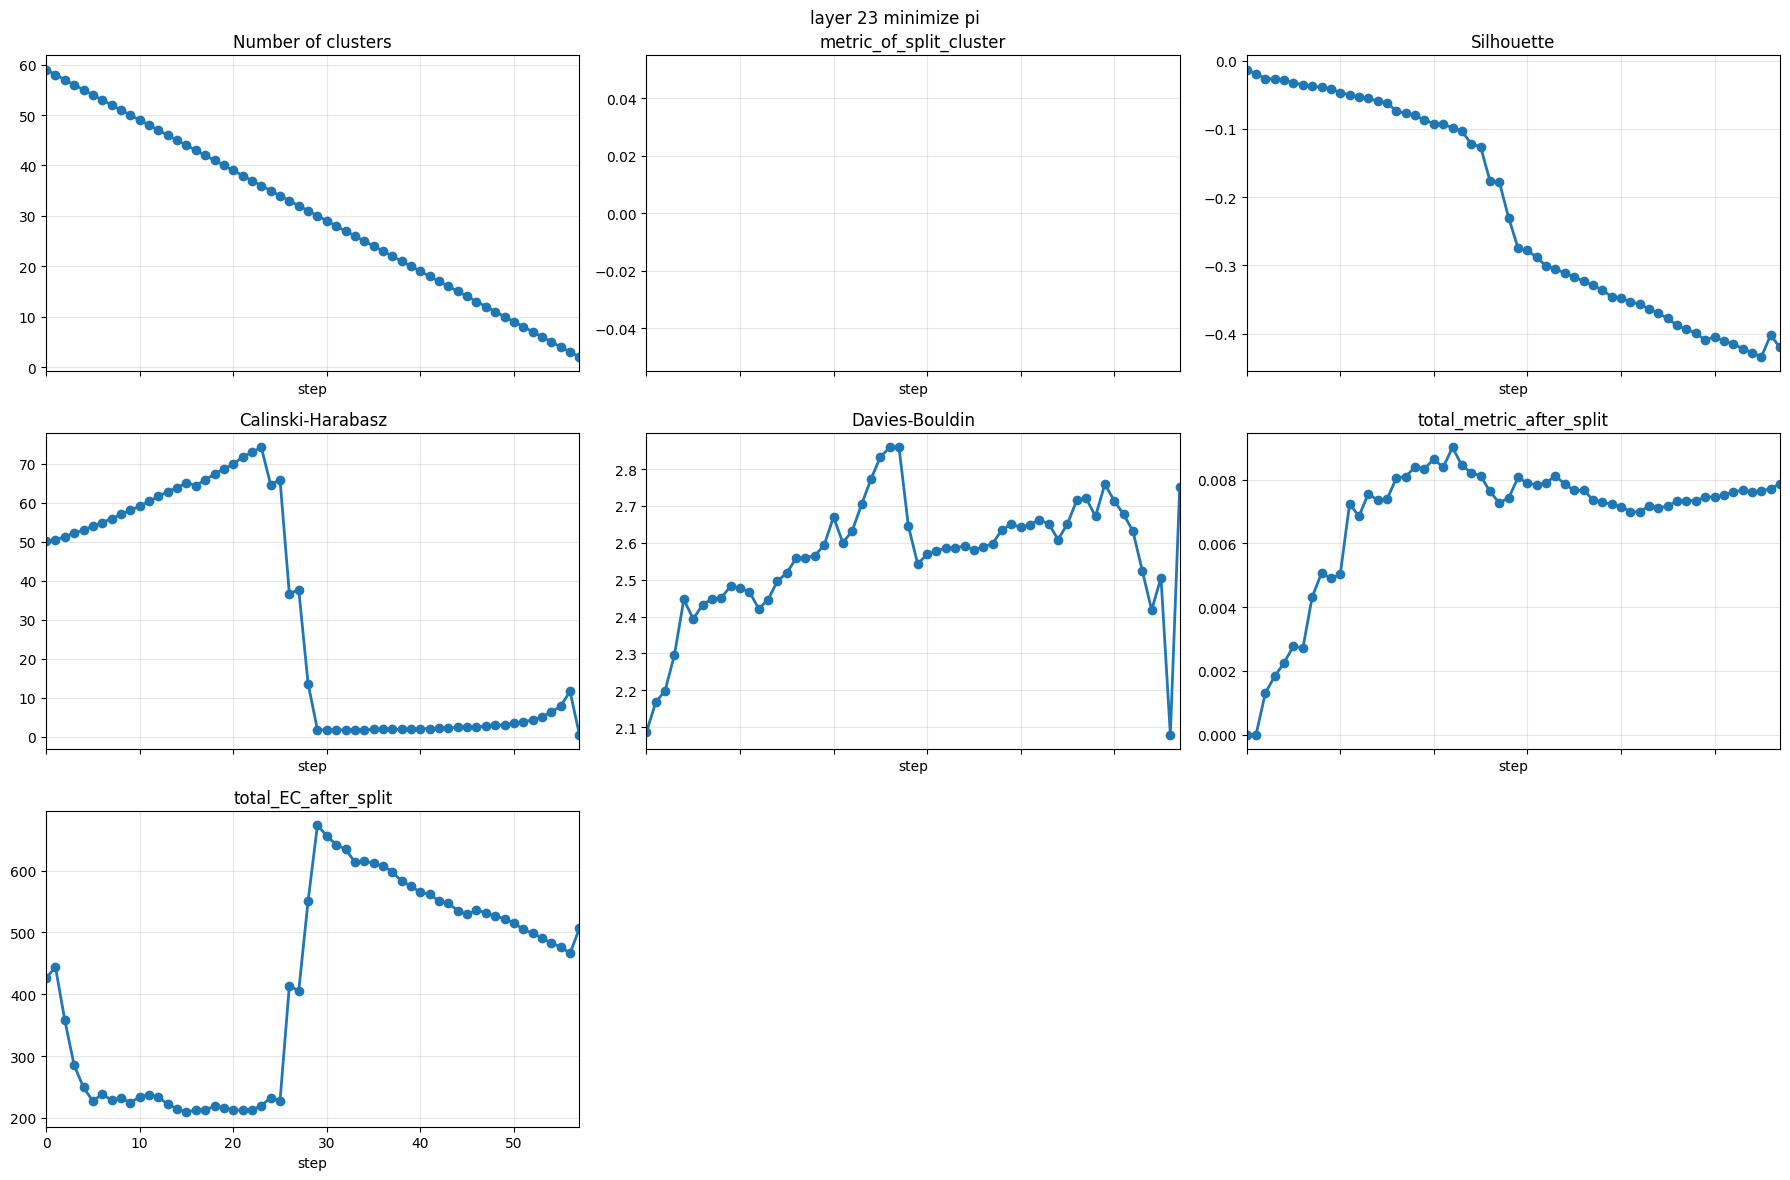

In [ ]:
name2activations = clusterer._get_activations_from_gate([layers[23]])
gate_activations = name2activations.items().__iter__().__next__()[1]
target_layer = layers[23]
gate_PI_matrix = ExpertLoggerDataConverter.compute_PI_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
gate_EC_matrix = ExpertLoggerDataConverter.compute_EC_matrix(model.num_experts, 
                                                             gate_activations, 
                                                             k = target_layer.moe.top_k)
clusters, history = find_by_agglomerative_clustering_2(gate_PI_matrix, 
                                                        maximize_metric=False, 
                                                        log_history=True,
                                                        other_matrices_for_stats={
                                                            'EC': gate_EC_matrix
                                                        })


layer_id = 23
layer_mask = embeddings["layer"].eq(layer_id)
X_layer = embs_only_full.loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = embeddings.loc[layer_mask, "expert"].to_numpy()

history_df = build_history_metrics_df(history, X_layer, row_experts)
history_df.tail(1)
plot_history_metrics(history_df, 'layer 23 minimize pi')

In [ ]:
history_df

,step,n_clusters,metric_of_split_cluster,total_metric_after_split,total_EC_after_split,silhouette,calinski_harabasz,davies_bouldin
0,0,59,NaN,0.000000,426.000000,-0.013349,50.139024,2.086157
1,1,58,NaN,0.000000,444.000000,-0.019311,50.454809,2.167786
2,2,57,NaN,0.001309,357.875000,-0.026292,51.332933,2.199536
3,3,56,NaN,0.001834,285.075000,-0.027199,52.213408,2.296283
4,4,55,NaN,0.002254,249.276660,-0.029108,52.991529,2.446417
5,5,54,NaN,0.002779,227.030948,-0.032299,54.032394,2.393854
6,6,53,NaN,0.002706,238.630354,-0.035520,54.935441,2.431522
7,7,52,NaN,0.004316,228.491753,-0.037044,55.950582,2.448103
8,8,51,NaN,0.005070,232.178016,-0.039378,57.004976,2.450098
9,9,50,NaN,0.004900,224.707546,-0.040967,58.052807,2.483063


In [ ]:
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import numpy as np

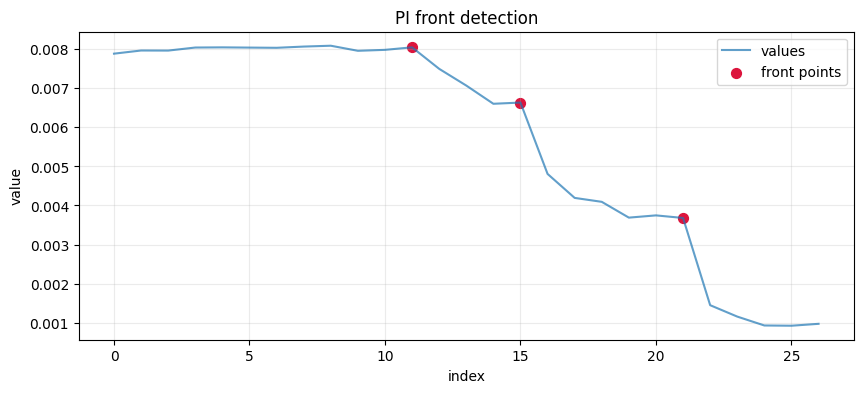

   idx     value  left_delta  right_delta  front_score  front_zscore
0   11  0.008045    0.000037     0.000990     0.001028      2.183691
1   15  0.006633   -0.000422     0.002268     0.001846      1.831488
2   21  0.003680   -0.000163     0.002501     0.002339      1.580630


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def detect_pi_front_points(
    values,
    skip_start=10,
    radius=3,
    neighborhood=3,
    z_threshold=1.0,
    min_curvature=0.0,
    require_local_peak=True,
):
    """Detect local front points on a curve.
    
    Args:
        values: numpy array or pandas Series of values
        skip_start: skip first N points
        radius: size of left/right window
        neighborhood: neighborhood size for local z-score
        z_threshold: z-score threshold for detection
        min_curvature: minimum front_score threshold
        require_local_peak: only accept local peaks
    
    Returns:
        DataFrame with detected front points (indices and scores)
    """
    values = np.asarray(values, dtype=np.float64)
    
    if values.size == 0:
        return pd.DataFrame()
    
    if values.size < max(skip_start + 2 * radius + 1, 2 * neighborhood + 1):
        return pd.DataFrame()

    front_score = np.full(len(values), np.nan, dtype=np.float64)
    left_delta = np.full(len(values), np.nan, dtype=np.float64)
    right_delta = np.full(len(values), np.nan, dtype=np.float64)

    start_idx = skip_start + radius
    stop_idx = len(values) - radius
    for idx in range(start_idx, stop_idx):
        left_window = values[idx - radius:idx]
        right_window = values[idx + 1:idx + 1 + radius]
        if left_window.size == 0 or right_window.size == 0:
            continue

        left_delta[idx] = values[idx] - left_window.mean()
        right_delta[idx] = values[idx] - right_window.mean()
        front_score[idx] = left_delta[idx] + right_delta[idx]

    score_series = pd.Series(front_score)
    local_mean = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).mean()
    local_std = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).std(ddof=0)
    score_z = (score_series - local_mean) / (local_std + 1e-12)

    if require_local_peak:
        local_max = score_series.rolling(window=2 * neighborhood + 1, center=True, min_periods=1).max()
        local_peak_mask = score_series.eq(local_max)
    else:
        local_peak_mask = pd.Series(True, index=score_series.index)

    candidate_mask = (
        np.arange(len(values)) >= start_idx
    ) & np.isfinite(front_score) & (front_score > min_curvature) & (score_z.to_numpy() > z_threshold) & local_peak_mask.fillna(False).to_numpy()

    indices = np.where(candidate_mask)[0]
    result = pd.DataFrame({
        'idx': indices,
        'value': values[indices],
        'left_delta': left_delta[indices],
        'right_delta': right_delta[indices],
        'front_score': front_score[indices],
        'front_zscore': score_z.to_numpy()[indices],
    })

    plt.figure(figsize=(10, 4))
    plt.plot(values, label="values", alpha=0.7)
    if len(result) > 0:
        plt.scatter(result['idx'], result['value'], color="crimson", s=50, label="front points")
    plt.title("PI front detection")
    plt.xlabel("index")
    plt.ylabel("value")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()

    return result


# Usage example with one of the history dataframes
if 'history_df_23_max_EC' in dir():
    values_series = history_df_23_max_EC['total_PI_after_split'].to_numpy()
    front_points_pi = detect_pi_front_points(
        values_series,
        skip_start=5,
        radius=3,
        neighborhood=3,
        z_threshold=1.0,
        min_curvature=0.0,
        require_local_peak=True,
    )
    print(front_points_pi)


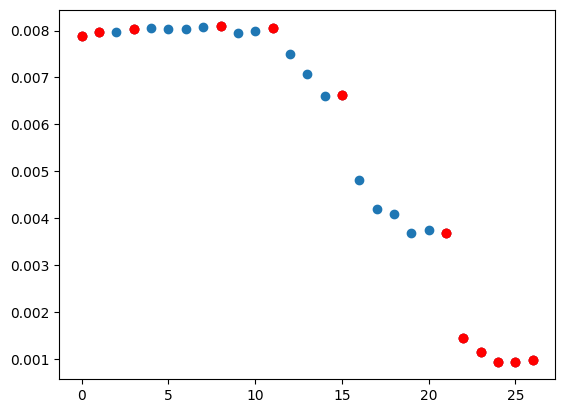

In [ ]:
def plot_simplex(history_df_23_max_EC):
    points_23_pi = np.array(list(zip(history_df_23_max_EC['total_PI_after_split'].index.to_list(), history_df_23_max_EC['total_PI_after_split'])))
    hull = ConvexHull(points_23_pi)
    plt.plot(points_23_pi[:,0], points_23_pi[:,1], 'o')
    for simplex in hull.simplices:
        plt.scatter(points_23_pi[simplex, 0], points_23_pi[simplex, 1], c='r', zorder=2)

plot_simplex(history_df_23_max_EC)

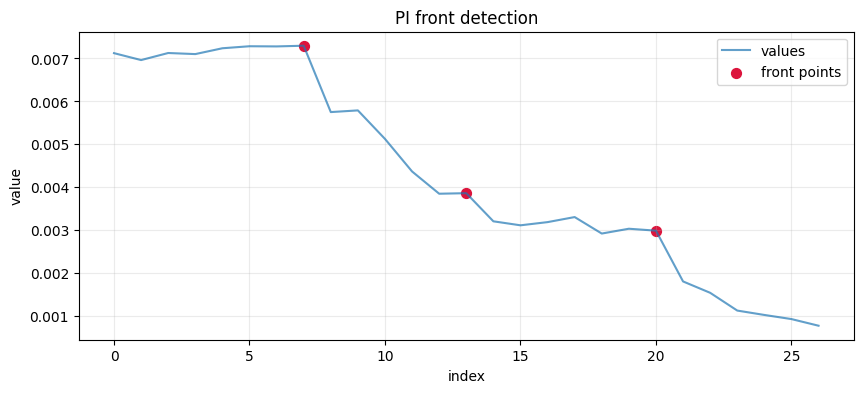

In [ ]:
front_points_pi = detect_pi_front_points(
    history_df_0_max_ec['total_PI_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

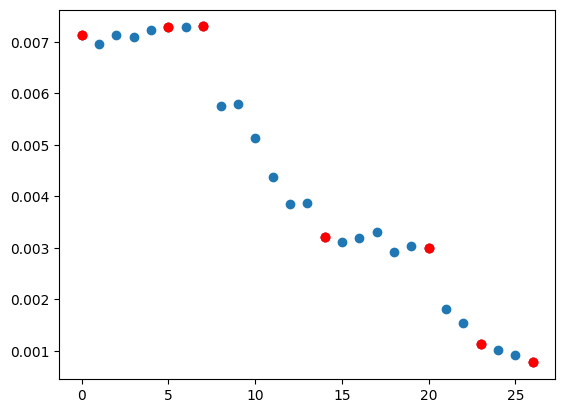

In [ ]:
plot_simplex(history_df_0_max_ec)

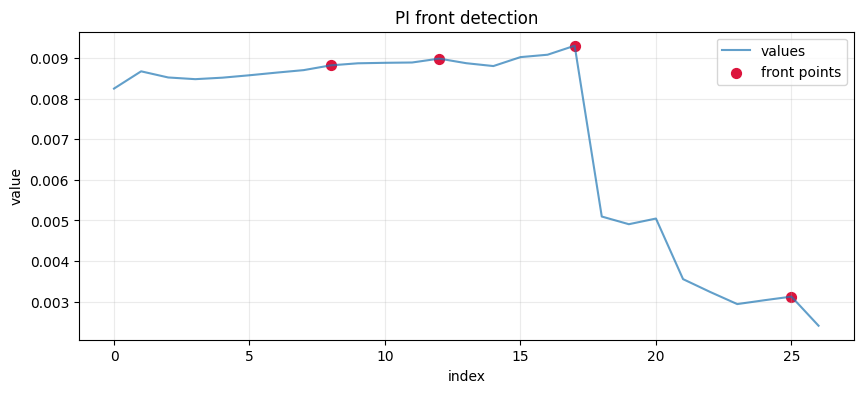

In [ ]:
front_points_pi = detect_pi_front_points(
    history_df_11_max_ec['total_PI_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

In [ ]:
points_11 = np.array(list(zip(history_df_11_max_ec['total_PI_after_split'].index.to_list(), history_df_11_max_ec['total_PI_after_split'])))

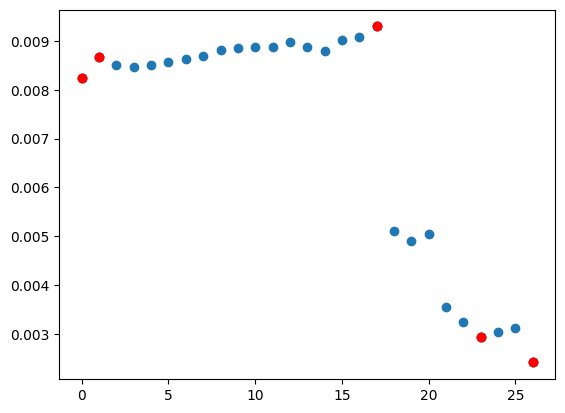

In [ ]:

points = history_df_11_max_ec['total_PI_after_split']   # 30 random points in 2-D
hull = ConvexHull(points_11)
plt.plot(points_11[:,0], points_11[:,1], 'o')
for simplex in hull.simplices:
    plt.scatter(points_11[simplex, 0], points_11[simplex, 1], c='r', zorder=2)

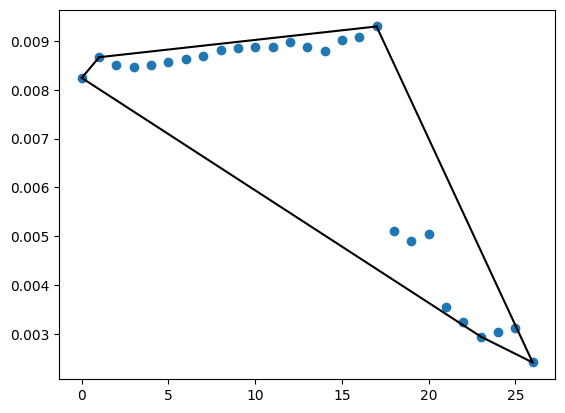

In [ ]:
plt.plot(points_11[:,0], points_11[:,1], 'o')
for simplex in hull.simplices:
    plt.plot(points_11[simplex, 0], points_11[simplex, 1], 'k-')

In [ ]:
hull.simplices

array([[17, 26],
       [ 1,  0],
       [ 1, 17],
       [23,  0],
       [23, 26]], dtype=int32)

In [ ]:
hull.vertices

array([26, 17,  1,  0, 23], dtype=int32)

How it works for EC?? Bad

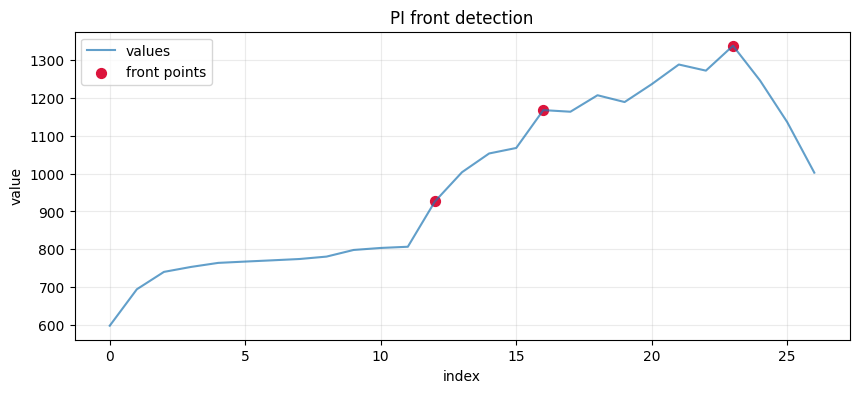

In [ ]:
front_points_pi = detect_pi_front_points(
    history_df_23_max_EC['total_metric_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

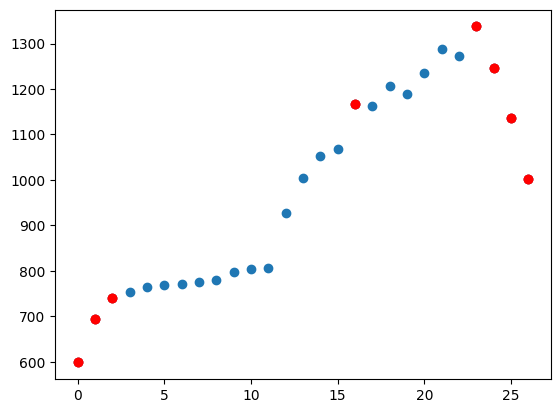

In [ ]:
points_23 = np.array(list(zip(history_df_23_max_EC['total_metric_after_split'].index.to_list(), history_df_23_max_EC['total_metric_after_split'])))
hull = ConvexHull(points_23)
plt.plot(points_23[:,0], points_23[:,1], 'o')
for simplex in hull.simplices:
    plt.scatter(points_23[simplex, 0], points_23[simplex, 1], c='r', zorder=2)

В общем с симплексом надо будет повозиться, пока оставим так.

In [ ]:
front_points_pi['idx'].to_list()

[12, 16, 23]

test

In [ ]:
from MoE_Optimization.common import expert_clusterer
import importlib
importlib.reload(expert_clusterer)


gen = MMLUBatchGenerator(subjects=SELECTED_TASKS, split='validation', batch_size=16, include_metadata=False)
example_inputs = convert_inputs_to_tokens(gen, tokenizer, model.device)
clusterer = expert_clusterer.ExpertClusterer(model, example_inputs)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Initialized MMLU batch generator with 5 subjects
Split: validation, Batch size: 16

📚 Loading subject 1/5: anatomy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 14 questions

📚 Loading subject 2/5: machine_learning


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 3/5: management


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 11 questions

📚 Loading subject 4/5: philosophy


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'cais/mmlu' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  ✓ Created batch with 16 questions

📚 Loading subject 5/5: world_religions
  ✓ Created batch with 16 questions


In [ ]:
layers = discover_moe_layers(model)

# name2act = clusterer._get_all_activations([layers[0]])

In [ ]:
layers[0].moe.top_k

4

In [ ]:
target_layers = [layers[0]]

In [ ]:
experts_names = [clusterer.module2name[expert]
                              for handle in target_layers for expert in handle.experts] #we need here 60 different experts with different activations
experts_names

['model.layers.0.mlp.experts.0',
 'model.layers.0.mlp.experts.1',
 'model.layers.0.mlp.experts.2',
 'model.layers.0.mlp.experts.3',
 'model.layers.0.mlp.experts.4',
 'model.layers.0.mlp.experts.5',
 'model.layers.0.mlp.experts.6',
 'model.layers.0.mlp.experts.7',
 'model.layers.0.mlp.experts.8',
 'model.layers.0.mlp.experts.9',
 'model.layers.0.mlp.experts.10',
 'model.layers.0.mlp.experts.11',
 'model.layers.0.mlp.experts.12',
 'model.layers.0.mlp.experts.13',
 'model.layers.0.mlp.experts.14',
 'model.layers.0.mlp.experts.15',
 'model.layers.0.mlp.experts.16',
 'model.layers.0.mlp.experts.17',
 'model.layers.0.mlp.experts.18',
 'model.layers.0.mlp.experts.19',
 'model.layers.0.mlp.experts.20',
 'model.layers.0.mlp.experts.21',
 'model.layers.0.mlp.experts.22',
 'model.layers.0.mlp.experts.23',
 'model.layers.0.mlp.experts.24',
 'model.layers.0.mlp.experts.25',
 'model.layers.0.mlp.experts.26',
 'model.layers.0.mlp.experts.27',
 'model.layers.0.mlp.experts.28',
 'model.layers.0.mlp.exp

In [ ]:
layers[0]

MoeHandle(layer_idx=0, moe=Qwen2MoeSparseMoeBlock(
  (gate): Linear4bit(in_features=2048, out_features=60, bias=False)
  (experts): ModuleList(
    (0-59): 60 x Qwen2MoeMLP(
      (gate_proj): Linear4bit(in_features=2048, out_features=1408, bias=False)
      (up_proj): Linear4bit(in_features=2048, out_features=1408, bias=False)
      (down_proj): Linear4bit(in_features=1408, out_features=2048, bias=False)
      (act_fn): SiLUActivation()
    )
  )
  (shared_expert): Qwen2MoeMLP(
    (gate_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
    (up_proj): Linear4bit(in_features=2048, out_features=5632, bias=False)
    (down_proj): Linear4bit(in_features=5632, out_features=2048, bias=False)
    (act_fn): SiLUActivation()
  )
  (shared_expert_gate): Linear4bit(in_features=2048, out_features=1, bias=False)
), gate=Linear4bit(in_features=2048, out_features=60, bias=False), experts=ModuleList(
  (0-59): 60 x Qwen2MoeMLP(
    (gate_proj): Linear4bit(in_features=2048, out_featur

In [ ]:
name2activ = clusterer._get_activations([experts_names[0]])
name2activ

{'model.layers.0.mlp.experts.0': [tensor([[ 0.0598, -0.0755,  0.0207,  ..., -0.0018,  0.0476, -0.0067],
          [-0.0989, -0.0221,  0.0396,  ..., -0.0368,  0.0229, -0.0151],
          [ 0.0445, -0.0933,  0.0228,  ..., -0.0884,  0.0600, -0.0417],
          ...,
          [ 0.0199,  0.0418,  0.0085,  ..., -0.0164, -0.0197, -0.0293],
          [-0.0049, -0.0071, -0.0046,  ..., -0.0096,  0.0078, -0.0062],
          [-0.0044,  0.0012, -0.0043,  ..., -0.0005,  0.0052, -0.0062]],
         device='cuda:0', dtype=torch.float16),
  tensor([[-0.0782,  0.0002, -0.1100,  ..., -0.0671,  0.0833,  0.0845],
          [ 0.0017, -0.0300,  0.0039,  ...,  0.0045, -0.0187,  0.0287],
          [-0.0166,  0.0072, -0.0083,  ..., -0.0023,  0.0039, -0.0028],
          ...,
          [-0.0220, -0.0083,  0.0418,  ..., -0.0048,  0.0160,  0.0284],
          [-0.0153, -0.0082,  0.0434,  ...,  0.0018,  0.0267,  0.0313],
          [-0.0049, -0.0071, -0.0046,  ..., -0.0096,  0.0078, -0.0062]],
         device='cuda:0'

In [ ]:
# ExpertLoggerDataConverter._transform_activations_for_analysis(name2activ)


In [ ]:
name2activ['model.layers.0.mlp.experts.0'][0].shape

torch.Size([22, 2048])

In [ ]:
model.model.layers[0].mlp.experts.parameters().__iter__().__next__().shape

torch.Size([1441792, 1])

In [ ]:
model.model.layers[0].mlp.top_k

4

In [ ]:
name2activations = clusterer.get_activations([layers[23], layers[0]], attach_to_gate_layer=True, attach_to_expert_layer=True)
name2activations

{'model.layers.0.mlp.gate': [tensor([[-3.9551, -4.0977, -3.8164,  ..., -5.0000, -3.7852, -5.3125],
          [-3.4141, -3.2266, -4.5547,  ..., -4.1680, -4.8320, -3.9199],
          [-3.5195, -4.1797, -4.2148,  ..., -3.6602, -4.6133, -4.9766],
          ...,
          [-4.3906, -3.5605, -5.8633,  ..., -4.3242, -5.0586, -8.7500],
          [-4.5000, -2.9297, -5.7383,  ..., -4.2891, -5.5625, -8.8047],
          [-4.2148, -3.7402, -5.5234,  ..., -3.6016, -5.1289, -8.5625]],
         device='cuda:0', dtype=torch.float16),
  tensor([[-3.9551, -4.0977, -3.8145,  ..., -5.0000, -3.7852, -5.3125],
          [-3.4141, -3.2266, -4.5547,  ..., -4.1680, -4.8320, -3.9199],
          [-3.5195, -4.1797, -4.2148,  ..., -3.6602, -4.6133, -4.9766],
          ...,
          [-4.2266, -4.4297, -5.3906,  ..., -3.4102, -6.1562, -6.8633],
          [-4.1133, -4.3008, -5.0898,  ..., -3.5469, -5.9727, -6.8750],
          [-4.0273, -4.2227, -5.0000,  ..., -3.5723, -5.7812, -7.0547]],
         device='cuda:0', dty

In [ ]:
import re
pattern = re.compile(r"model\.layers\.(\d+)\.mlp\.experts\.(\d+)")
result = {}
for key in name2activations.keys():
    m = pattern.match(key)
    if m:
        layer = int(m.group(1))
        expert = int(m.group(2))
        if layer == 23:
            result[expert] = name2activations[key]
result[59].__len__()

5

In [ ]:
result[59]

[tensor([[ 0.1226,  0.7837, -0.2411,  ..., -0.6157, -0.1740, -0.8086],
         [-0.2983,  0.0501, -0.3447,  ..., -0.3730,  0.9443, -0.5400],
         [-1.1152, -0.0906, -0.0197,  ..., -0.3228,  0.1390, -1.9775],
         ...,
         [-0.1449, -0.3547,  0.2256,  ..., -1.4277, -0.2952, -0.5894],
         [-0.6025, -0.3804, -0.8516,  ..., -0.8081, -0.4622, -1.1699],
         [-0.9487, -0.1902,  0.2734,  ..., -0.9219, -0.3088, -1.0742]],
        device='cuda:0', dtype=torch.float16),
 tensor([[-0.1995,  0.3684, -0.0912,  ...,  0.3467,  0.1584, -0.4548],
         [ 1.0830, -2.9453, -0.4236,  ..., -0.9502, -1.7158,  1.1582],
         [-0.2847, -2.1973,  1.0664,  ...,  1.3916,  3.0781,  2.4004],
         ...,
         [ 1.9033, -0.8618, -0.5435,  ..., -0.6191, -0.6519,  0.5718],
         [ 1.4512,  0.1143, -0.6670,  ..., -1.6133, -0.3977,  1.4951],
         [ 1.3750,  0.0462, -0.8525,  ...,  2.0273, -0.1140, -1.3965]],
        device='cuda:0', dtype=torch.float16),
 tensor([[ 0.3416, -0.17

In [ ]:
embeddings = {e: torch.mean(e_vals, dim=1) for e, e_vals in result.items()}
# embeddings

TypeError: mean() received an invalid combination of arguments - got (list, dim=int), but expected one of:
 * (Tensor input, *, torch.dtype dtype = None, Tensor out = None)
 * (Tensor input, tuple of ints dim, bool keepdim = False, *, torch.dtype dtype = None, Tensor out = None)
 * (Tensor input, tuple of names dim, bool keepdim = False, *, torch.dtype dtype = None, Tensor out = None)


In [ ]:
def _parse_kind(self, layer, task):
        path: Path = f'{self.layer_prefix}.{layer}.{self.expert_infix}'
        task = self.task_to_idx[task]
        for expert in self.root.iterdir():
            if not str(path) in expert.name:
                continue
            n = int(expert.name.split('.')[-1])
            file = expert /  f'{task}.pth'
            if file.exists():
                t = torch.load(file, map_location='cuda:0').cpu()
                self.expert_to_idx_num[task][n] = t.size(0)
                yield n, t



In [ ]:
from functools import partial
from typing import Callable, Iterable, Literal

from networkx import clustering
from torch import func
from MoE_Optimization.common.expert_logger import ExpertsLogger
from MoE_Optimization.common.expert_logger_data_converter import ExpertLoggerDataConverter
from MoE_Optimization.common.expert_matcher import ExpertMatcher
from MoE_Optimization.common.moe_utils import MoeHandle, discover_moe_layers
import torch

class ExpertClusterer2:
    def __init__(self, model: torch.nn.Module, example_inputs: Iterable, ):
        self.module2name = {m: n for n, m in model.named_modules()}
        self.model = model
        self.example_inputs = example_inputs
        self.experts_logger = partial(ExpertsLogger, model=model)
        self.moe_handles: list[MoeHandle] = discover_moe_layers(model)
        
    def parse_experts(self, name2activations, layer: int):
        pattern = re.compile(r"model\.layers\.(\d+)\.mlp\.experts\.(\d+)")
        result = {}
        for key in name2activations.keys():
            m = pattern.match(key)
            if m:
                layer_found = int(m.group(1))
                expert = int(m.group(2))
                if layer_found == layer:
                    result[expert] = name2activations[key]
        return result #dict[expert_id, tensor] 60 items for qwen

    def get_tasks_expert_embeddings(self, name2activations, aggregation: Literal['mean', 'max']='mean', layers=None):
            res = []
            layers = layers or [0]

            for layer in layers:
                experts = self.parse_experts(name2activations, layer)

                if aggregation == 'max':
                    pass
                    #embeddings = {e: activations[torch.argmax(torch.linalg.norm(activations, dim=-1))] for e, activations in experts.items()}
                elif aggregation == 'mean':
                    for e, e_vals in experts.items():
                        for e_topic in e_vals:
                            embedding = torch.mean(e_topic, dim=0)
                            res.append(
                                (layer, e, *embedding.cpu().numpy())
                            )
                else:
                    raise ValueError(f'Unknown aggregation: {aggregation}. Supported max, mean')
                    
            res = pd.DataFrame(res, columns=('layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 2)]))
            return res 

In [ ]:
clusterer2 = ExpertClusterer2(model, example_inputs)

In [ ]:
range(len(clusterer2.example_inputs))

range(0, 5)

In [ ]:
experts = clusterer2.parse_experts(23)

In [ ]:
df_embs = clusterer2.get_tasks_expert_embeddings(layers=[23, 0])

In [ ]:
df_embs[df_embs['layer']==0]

/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/glazkov-dev/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
299,0,0,0.001871,0.009819,0.011375,-0.005093,-0.023453,0.000693,-0.006336,0.003016,...,-0.017487,-0.033661,-0.001589,0.011383,0.019379,-0.004185,0.002098,0.002905,0.016327,0.013466
300,0,0,-0.005535,-0.000742,0.003492,-0.007046,-0.001833,0.001842,-0.008064,0.004166,...,-0.010796,0.013992,0.001933,0.005718,-0.012360,0.004234,-0.007675,0.002676,0.001270,0.000847
301,0,0,-0.030777,0.033661,-0.012375,-0.009377,0.013229,-0.003052,0.012115,-0.000340,...,-0.007889,0.019684,0.015175,-0.016129,-0.002003,-0.017120,-0.009911,-0.030685,0.004360,0.003613
302,0,0,-0.017502,0.001801,-0.005836,-0.003752,0.001504,0.004421,-0.015160,-0.015572,...,-0.022949,0.000810,-0.008705,0.003273,-0.008011,-0.004932,-0.000004,0.003872,-0.011826,-0.002569
303,0,0,0.017227,0.007828,0.007095,0.001690,-0.002802,-0.006130,0.000272,0.004154,...,-0.005268,0.007008,0.004322,0.002972,0.002026,0.004570,-0.009361,-0.005100,0.028793,0.016220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591,0,59,0.008949,-0.031403,0.056763,0.003105,-0.034637,-0.035217,-0.052368,-0.003281,...,0.034912,-0.025330,0.014854,-0.020279,0.048248,-0.004414,0.014687,0.040344,0.036041,-0.017975
592,0,59,-0.010277,-0.013809,-0.005913,0.001413,-0.017761,0.014809,0.000308,-0.004967,...,-0.002705,-0.006653,-0.006214,0.010979,-0.016296,0.000683,0.003281,-0.011467,-0.005665,0.000600
593,0,59,-0.005157,-0.041504,0.035919,-0.030380,-0.005905,-0.038239,-0.003239,-0.027435,...,0.016327,0.007473,0.002438,0.022476,0.019119,0.034241,-0.016327,0.050812,-0.001297,-0.002655
594,0,59,0.001328,0.012856,-0.005478,0.020416,-0.009247,-0.012840,0.008682,-0.030609,...,0.014191,0.012985,-0.049408,0.015236,-0.042725,-0.005585,-0.006042,-0.008751,-0.015480,-0.011810


In [ ]:
def build_calinski_score_df(history, X, row_experts):
    rows = []

    for step, entry in enumerate(history):
        clusters = entry.get("all_clusters", entry.get("clusters"))
        if clusters is None or len(clusters) < 2:
            continue

        labels = labels_from_clusters(clusters, row_experts) #insted of series of expert indices makes indices of clusters
        valid_mask = labels >= 0
        X_step = X[valid_mask]
        labels_step = labels[valid_mask]

        if X_step.shape[0] < 2 or np.unique(labels_step).size < 2:
            continue

        row = {
            "step": step,
            "n_clusters": len(clusters),
            "total_PI_after_split": entry["total_PI_after_split"]
        }

        try:
            row["calinski_harabasz"] = calinski_harabasz_score(X_step, labels_step)
        except Exception:
            row["calinski_harabasz"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)


layer_id = 23
layer_mask = df_embs["layer"].eq(layer_id)
X_layer = df_embs.drop(['layer', 'expert'], axis=1).loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = df_embs.loc[layer_mask, "expert"].to_numpy()

history_df = build_calinski_score_df(history, X_layer, row_experts)
display(history_df)
print("history_df length:", len(history_df))

""


history_df length: 0


In [ ]:
target_layers = [layers[23], layers[0]]
name2activations = clusterer.get_activations(target_layers, attach_to_gate_layer=True, attach_to_expert_layer=True)
def is_gate(name: str, layer: torch.nn.Module = None):
    return name.endswith('gate')


for layer_name in name2activations.keys():
    # if (is_gate(layer_name)): #DONT NEED IN OLD VERSION OF transformers, but need in new ones
    #     activations[layer_name] = [gate[0] for gate in activations[layer_name]] #get raw logits from tuple (logits, topk scroes, topk indices)
    if (is_gate(layer_name)): #we need activations without batches on topics/tasks. but for embeddings we need distinct batches for mean aggregation in future
        name2activations[layer_name] = torch.cat(name2activations[layer_name])
name2activations

{'model.layers.0.mlp.gate': tensor([[-3.9551, -4.0977, -3.8164,  ..., -5.0000, -3.7852, -5.3125],
         [-3.4141, -3.2266, -4.5547,  ..., -4.1680, -4.8320, -3.9199],
         [-3.5195, -4.1797, -4.2148,  ..., -3.6602, -4.6133, -4.9766],
         ...,
         [-3.8066, -3.7910, -5.2305,  ..., -3.8066, -6.1445, -7.8398],
         [-3.7559, -3.7832, -5.0195,  ..., -3.9141, -6.5898, -7.7344],
         [-3.8320, -3.8262, -4.9219,  ..., -3.9961, -6.6836, -7.6758]],
        device='cuda:0', dtype=torch.float16),
 'model.layers.0.mlp.experts.0': [tensor([[ 0.0598, -0.0755,  0.0207,  ..., -0.0018,  0.0476, -0.0067],
          [-0.0989, -0.0221,  0.0396,  ..., -0.0368,  0.0229, -0.0151],
          [ 0.0445, -0.0933,  0.0228,  ..., -0.0884,  0.0600, -0.0417],
          ...,
          [ 0.0199,  0.0418,  0.0085,  ..., -0.0164, -0.0197, -0.0293],
          [-0.0049, -0.0071, -0.0046,  ..., -0.0096,  0.0078, -0.0062],
          [-0.0044,  0.0012, -0.0043,  ..., -0.0005,  0.0052, -0.0062]],
     

In [ ]:
layer_gate_name = clusterer.module2name[layers[0].gate]
gate_activations = name2activations[layer_gate_name]
    
clustering_cases, history = clusterer.create_clusters_by_PI_front_points(layers[0], gate_activations, log_history=False)

In [ ]:
df_embs = clusterer2.get_tasks_expert_embeddings(name2activations, layers=0)

In [ ]:
layer_id = 0
layer_mask = df_embs["layer"].eq(layer_id)
X_layer = df_embs.drop(['layer', 'expert'], axis=1).loc[layer_mask].to_numpy(dtype=np.float64)
row_experts = df_embs.loc[layer_mask, "expert"].to_numpy()

history_df = build_calinski_score_df(history, X_layer, row_experts) #hghg
history_df

,step,n_clusters,total_PI_after_split,calinski_harabasz
0,0,2,0.007124,4.615364
1,1,3,0.006963,3.404603
2,2,4,0.007128,3.228320
3,3,5,0.007102,2.740450
4,4,6,0.007238,2.383993
5,5,7,0.007285,2.101483
6,6,8,0.007281,1.900083
7,7,9,0.007297,1.786379
8,8,10,0.005751,1.823972
9,9,11,0.005790,1.801605


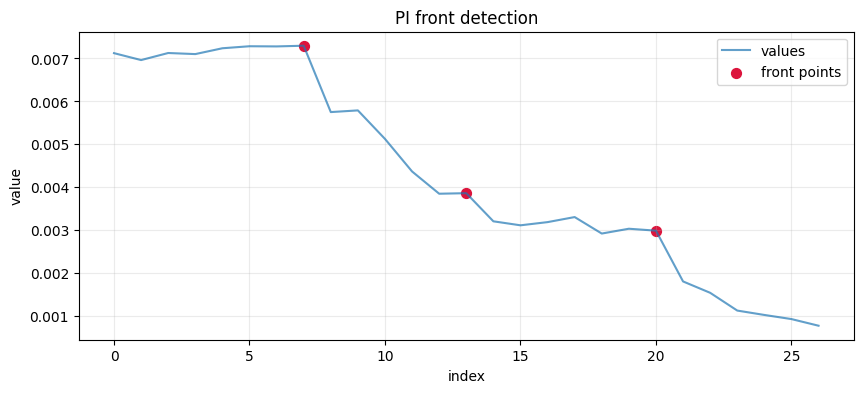

In [ ]:
front_points_pi = detect_pi_front_points(
    history_df['total_PI_after_split'],
    skip_start=5,
    radius=1,
    neighborhood=3,
    z_threshold=0.5,
    min_curvature=0.0,
    require_local_peak=True,
)

In [ ]:
front_points_pi['idx']

0     7
1    13
2    20
Name: idx, dtype: int64

In [ ]:
history_df['calinski_harabasz'][front_points_pi['idx']]

7     1.786379
13    3.379165
20    3.360117
Name: calinski_harabasz, dtype: float64

In [ ]:
history_df['calinski_harabasz'][front_points_pi['idx']].idxmax()

np.int64(13)

In [ ]:
#DONE
def find_best_point_by_calinski_score(front_points_pi_indexes, history_df, column_name='calinski_harabasz'):
    return history_df['calinski_harabasz'][front_points_pi['idx']].idxmax()

In [ ]:
history[13]['all_clusters'] #done!

[[45, 43, 51, 41, 48, 18, 31],
 [8, 25, 2, 1, 47, 53, 38],
 [29, 24, 42, 15],
 [30, 27],
 [40, 22],
 [39, 50],
 [20, 3],
 [36, 10],
 [11, 26],
 [44, 59, 0, 32, 55, 16, 35],
 [58, 7, 9, 14, 49, 5, 17, 13],
 [33, 28, 6, 19, 21, 46, 56],
 [34, 52, 12, 23],
 [4, 37],
 [57, 54]]

In [ ]:
for target_layer_handler in target_layers:
    layer_gate_name = clusterer.module2name[target_layer_handler.gate]
    gate_activations = name2activations[layer_gate_name]
    
    clustering_cases, history = clusterer.create_clusters_by_PI_front_points(target_layer_handler, gate_activations, log_history=False, **kwargs)
    
    layer_idx2clusters[target_layer_handler.layer_idx] = clusters
    return layer_idx2clusters

SyntaxError: 'return' outside function (1056538103.py, line 8)

In [ ]:
clus0 = clusterer.create_clusters_by_front_PI_and_max_Calinski(layers[0])
clus0